# LSE Machine Learning: Practical Applications
## Module 8 Unit 2 IDE Activity (Assessment) | _k_-means and hierarchical clustering 

The instructions for this IDE activity are positioned as text cells before each step. You are required to read the text cells above a code cell, familiarise yourself with the required step, and execute the step. Note that you are required to execute all the code cells in this notebook, but are only required to complete some of the code in certain code cells throughout the notebook, which are indicated by **### BEGIN SOLUTION**, after which you are required to add your code. You will also find markdown cells you need to populate, which are indicate by **YOUR ANSWER HERE** text. You are encouraged to refer back to the practice IDE activity to familiarise yourself with the different steps and how they are executed in R.


#### 1. Load the relevant packages

For data manipulation, use the `tidyverse` package. `GGally`, `ggplot2`, `grid`, and `gridExtra` are used for plotting and visualising the data. The `cluster` package is used to perform *k*-means and hierarchical clustering.  

**Note:** 
* Do not change the random seed (`set.seed(123)`), as this will result in different results each time the code is executed. 
* To hide warnings that are irrelevant, `options(warn=-1)` is used.

In [1]:
# Hide warnings globally
options(warn=-1) 

# Load packages
library(tidyverse)
library(ggplot2)
library(cluster)
library(GGally) # Visualising the correlations
library(grid) # Plotting the grid 
library(gridExtra) # Plotting the grid

# Set random seed
set.seed(123)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.4     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Registered S3 method overwritten by 'GGally':
  method from   
  +.gg   ggplot2


Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




#### 2. Load the data sets

In [2]:
redWine <- read.csv("red_wine.csv", header = T,row.names = 1)
whiteWine <- read.csv("white_wine.csv", header = T, row.names = 1)

#### 3. Examine the two data sets by using the `dim` function

In [3]:
# Red wines
### BEGIN SOLUTION
dim(redWine)
### END SOLUTION

[1] 159  12

In [4]:
# White wines
### BEGIN SOLUTION
dim(whiteWine)
### END SOLUTION

[1] 489  12

#### 4. Combine the data sets and append the column `colour` to label wines as red or white

In [5]:
wine <- rbind(cbind(redWine,colour = "red"),
              cbind(whiteWine,colour = "white"))
wine

,fixed.acidity,volatile.acidity,citric.acid,residual.sugar,chlorides,free.sulfur.dioxide,total.sulfur.dioxide,density,pH,sulphates,alcohol,quality,colour
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<chr>
372,7.9,0.240,0.40,1.60,0.056,11,25,0.99670,3.32,0.87,8.7,6,red
1090,11.6,0.410,0.54,1.50,0.095,22,41,0.99735,3.02,0.76,9.9,7,red
16,8.9,0.620,0.19,3.90,0.170,51,148,0.99860,3.17,0.93,9.2,5,red
1003,9.1,0.290,0.33,2.05,0.063,13,27,0.99516,3.26,0.84,11.7,7,red
1580,6.2,0.560,0.09,1.70,0.053,24,32,0.99402,3.54,0.60,11.3,5,red
1069,11.1,0.310,0.53,2.20,0.060,3,10,0.99572,3.02,0.83,10.9,7,red
1191,9.1,0.400,0.57,4.60,0.080,6,20,0.99652,3.28,0.57,12.5,6,red
1036,10.1,0.370,0.34,2.40,0.085,5,17,0.99683,3.17,0.65,10.6,7,red
243,7.7,0.580,0.10,1.80,0.102,28,109,0.99565,3.08,0.49,9.8,6,red


**Note:**

- The first column is a random number to identify a wine, so it is a categorical variable.
- Most of the variables are numerical and are on different scales.
- The quality score is out of 10, which is an integer.
- ***Colour*** is a categorical variable.


#### 5. Explore density plots of the red and white groups for different variables 
**Note:** The density plot is a type of plot and is not related to the ***density*** variable in this data set.


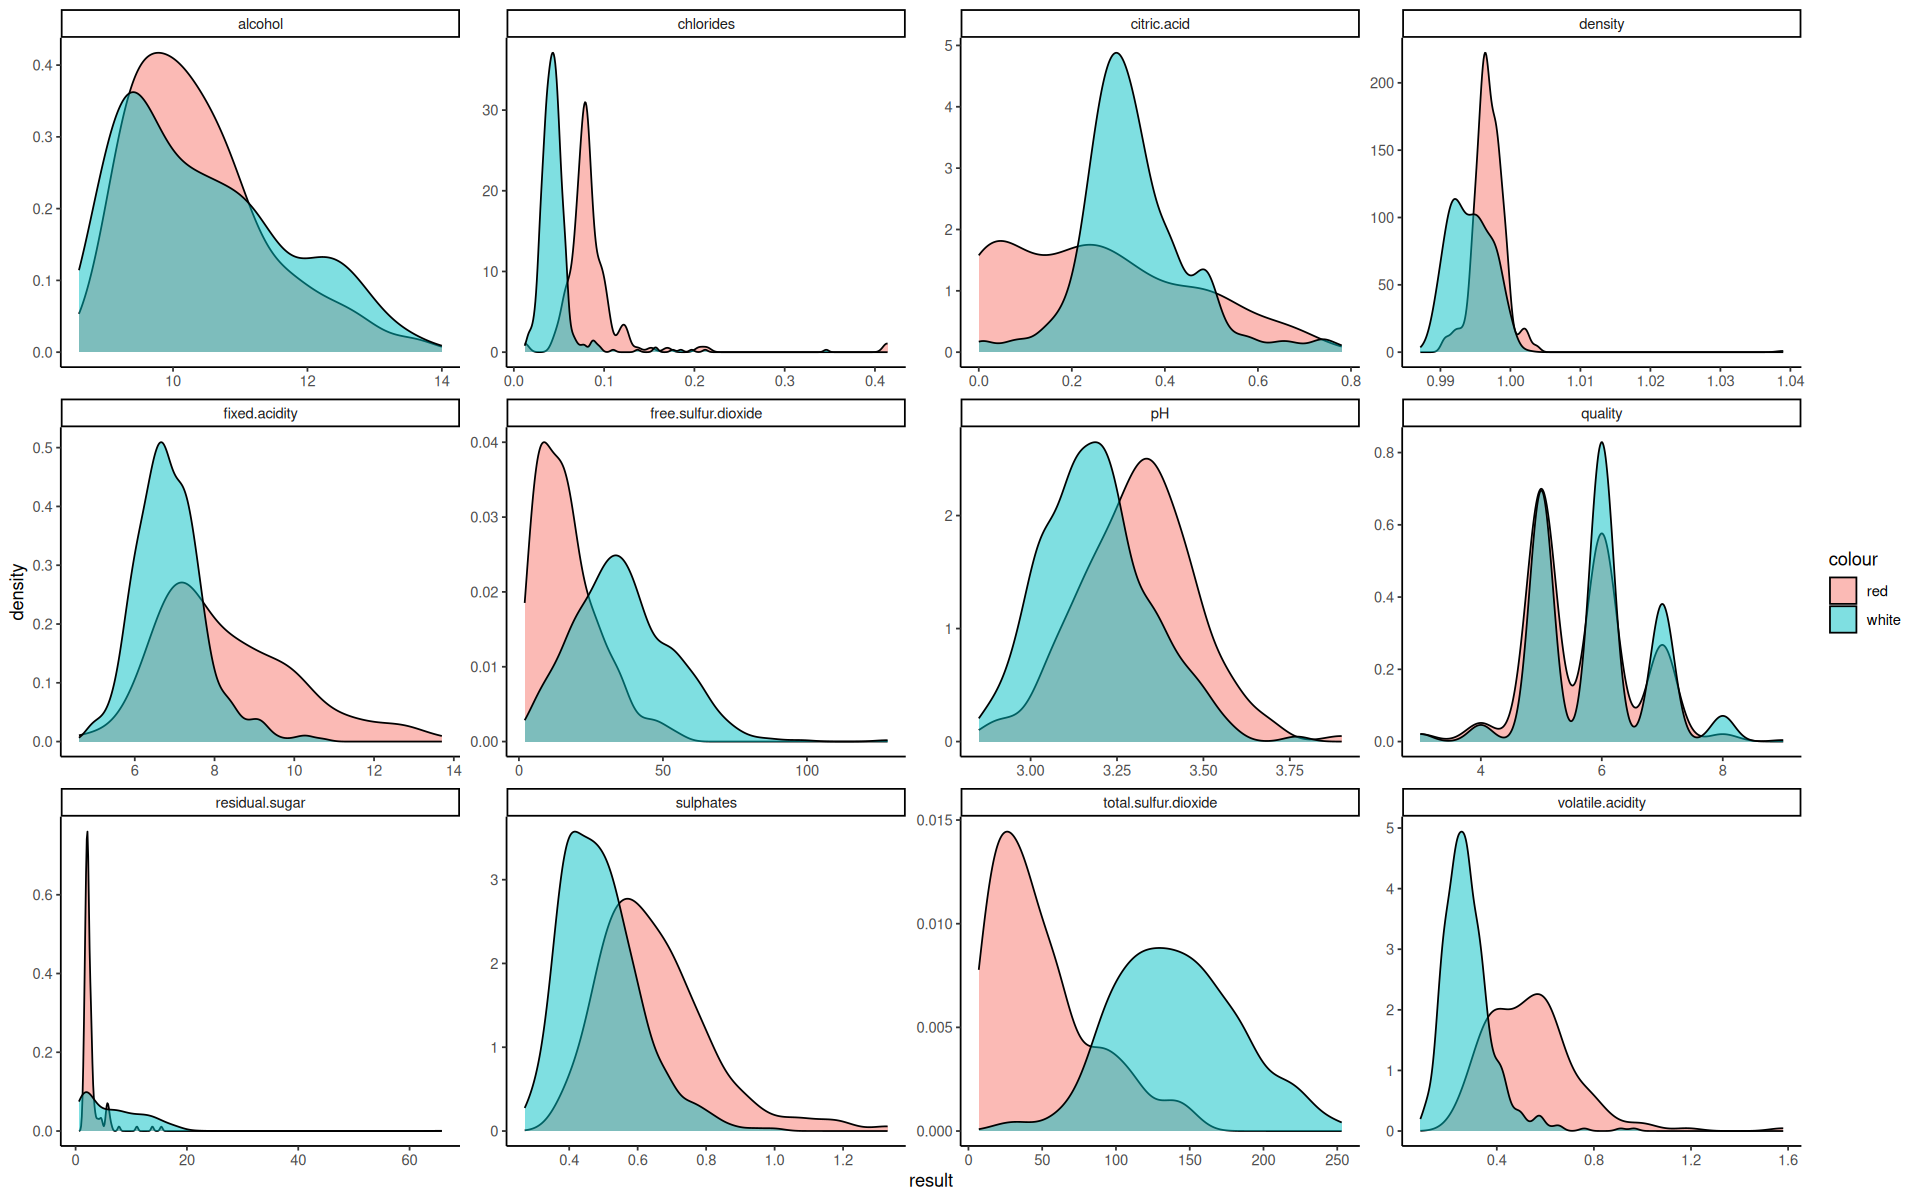

In [6]:
options(repr.plot.width=16, repr.plot.height=10)

wine %>% 
    gather(1:12, key = "variables", value = "result") %>%
    ggplot(aes(result, fill = colour)) +
    geom_density(alpha = 0.5)+
    theme_classic()+
    facet_wrap(.~variables, scale = "free")

**Pause and reflect:** 

Which variable distribution is the most different between red and white wines? Difference is determined by having little overlap with different peaks (average values).

#### 6. Consider the correlation between variables

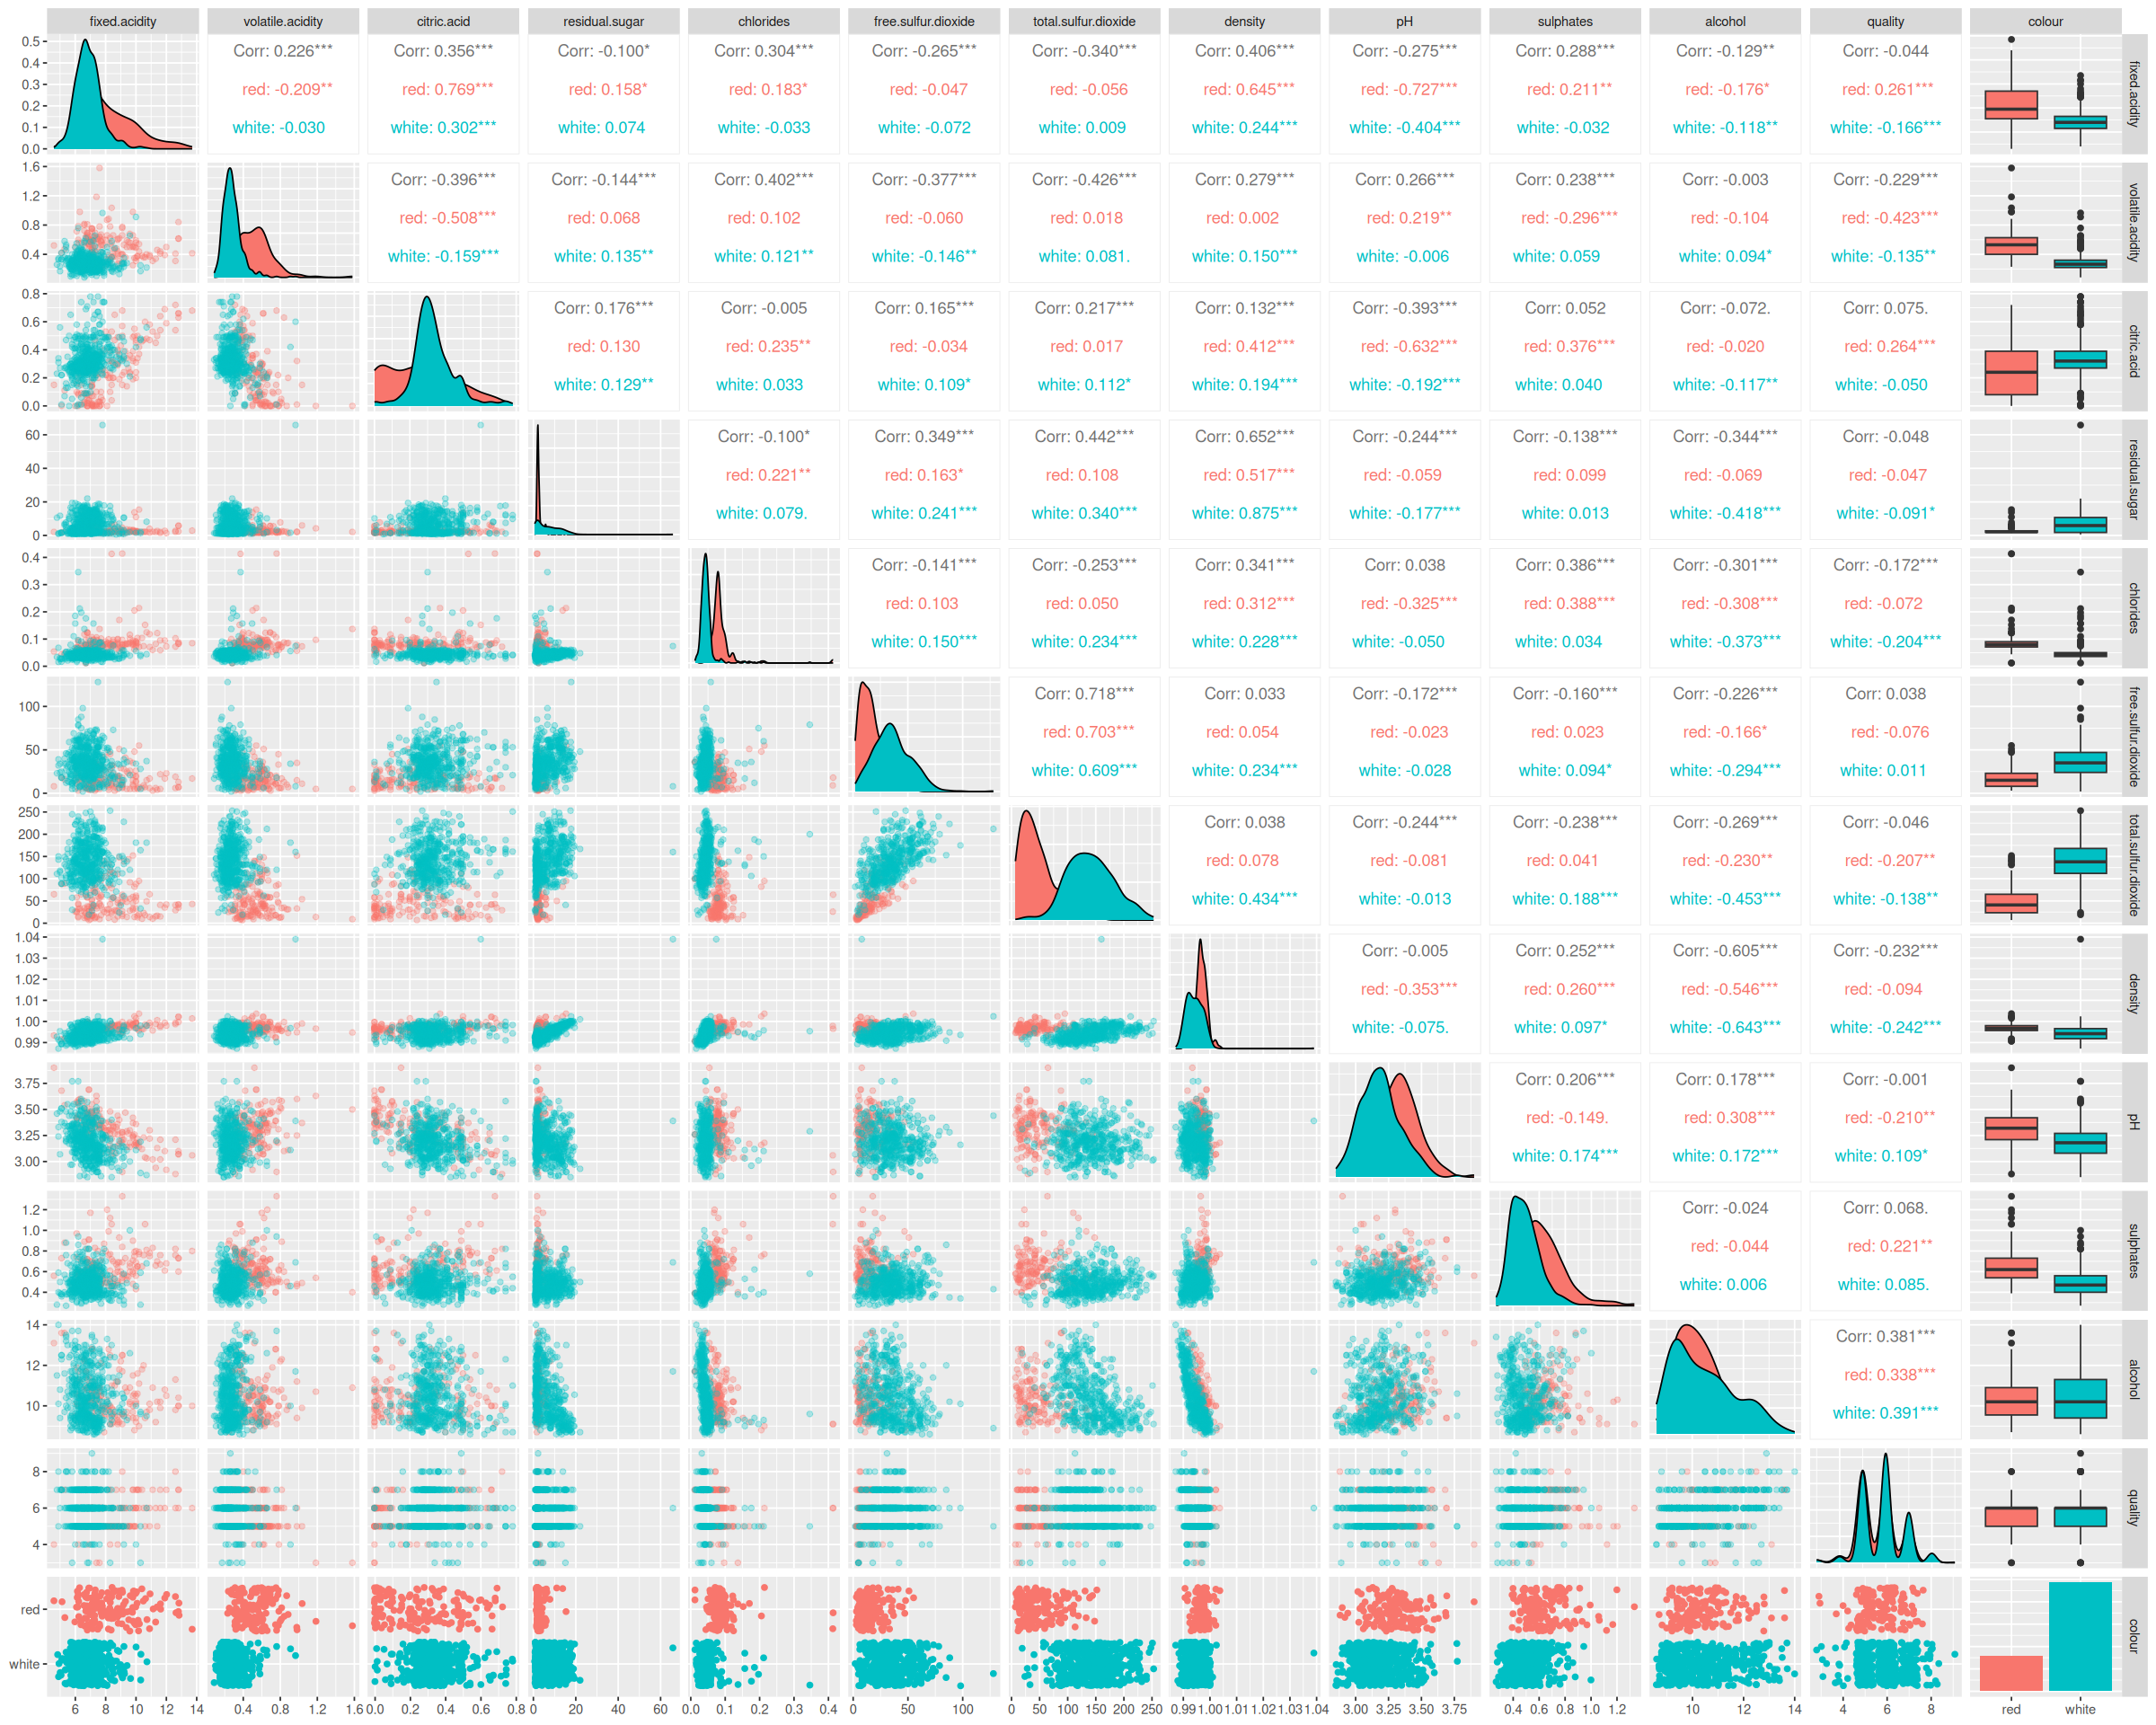

In [7]:
options(repr.plot.width=20, repr.plot.height=16)

ggpairs(wine, 
        mapping = ggplot2::aes(color = colour),
        lower = list(continuous = wrap("points", alpha = 0.3), combo ='dot_no_facet'),
        upper = list(combo = 'box_no_facet'))

**Pause and reflect:**

* Which variables are correlated? Which variables have a correlation greater than 0.2 or less than −0.2 when plotted against ***quality***?


#### 7. Explore potential drivers of quality using scatterplots

Given the insights from the data exploration, what questions can you ask? Can wines be segregated according to quality? What factors might drive the quality of red and white wines?

To determine which variables affect the quality of wines, the variables are plotted in the steps that follow.

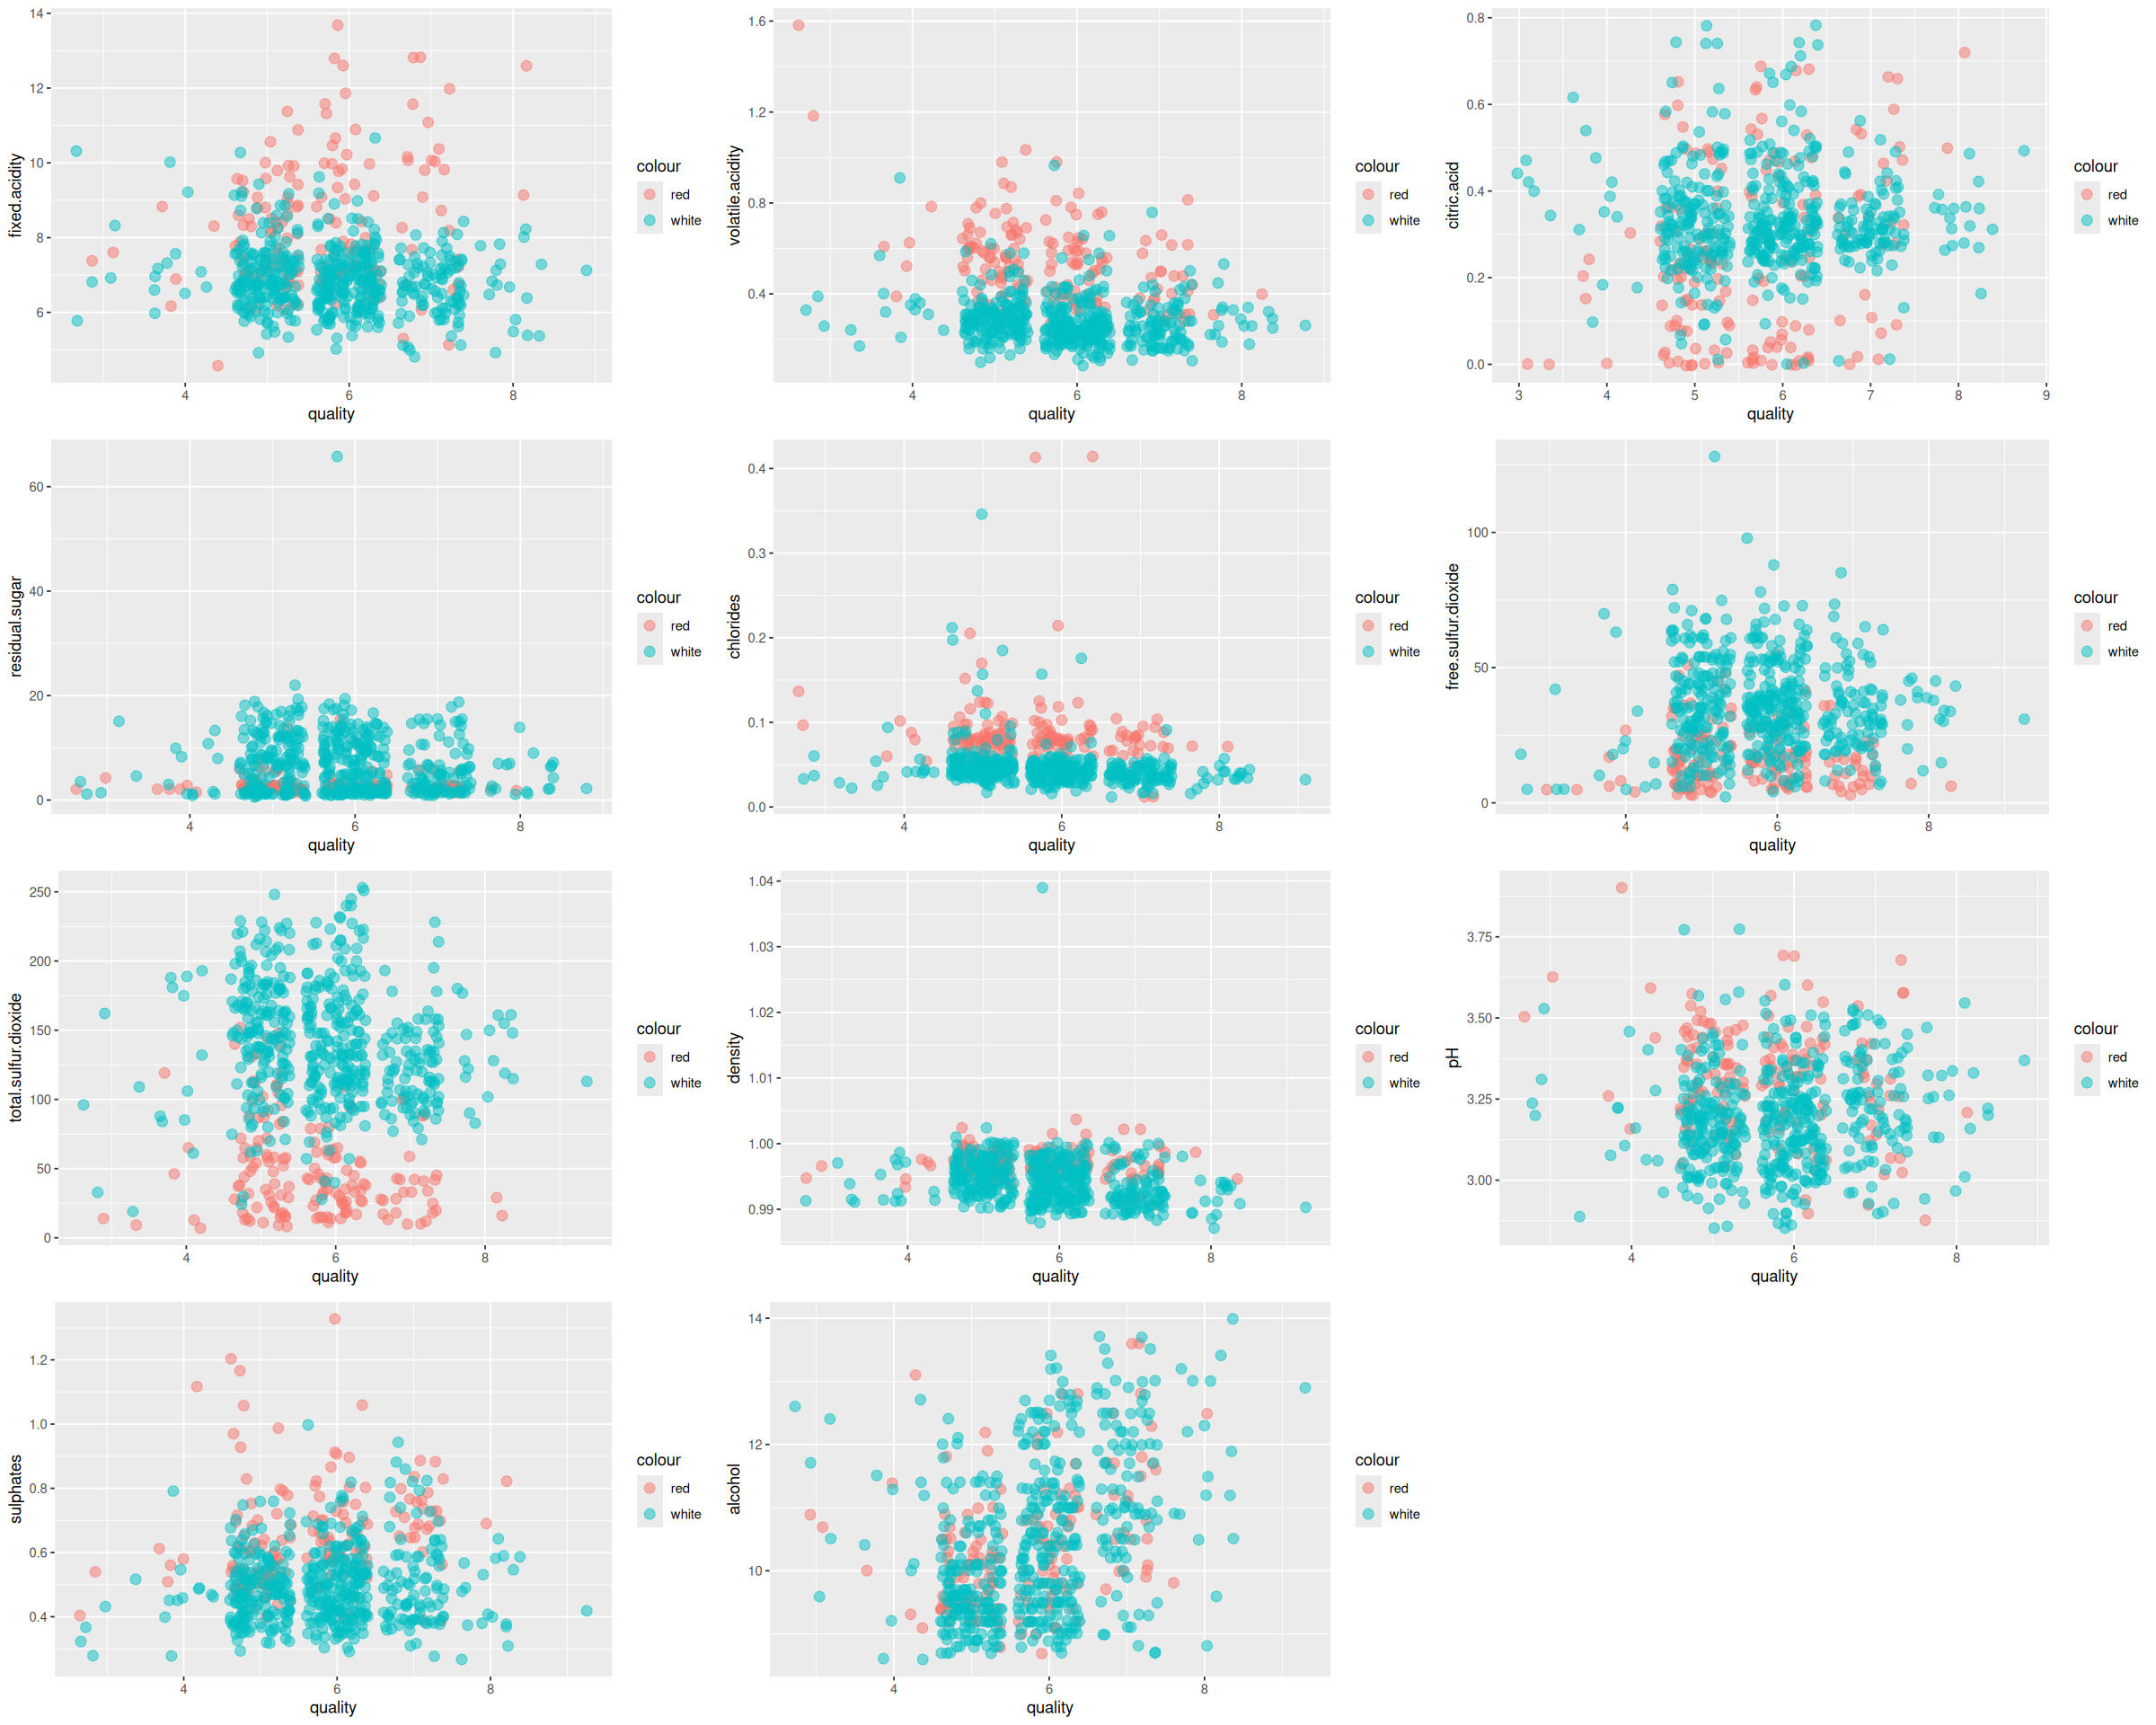

In [8]:
options(repr.plot.width=20, repr.plot.height=16)

p1 = wine  %>% 
    ggplot(aes(x = quality, y = fixed.acidity))+
    geom_jitter(aes(col=colour),size =3, alpha =0.5)

p2 = wine  %>% 
    ggplot(aes(x = quality, y = volatile.acidity))+
    geom_jitter(aes(col=colour),size =3, alpha =0.5)

p3 = wine  %>% 
    ggplot(aes(x = quality, y = citric.acid))+
    geom_jitter(aes(col=colour),size =3, alpha =0.5)

p4 = wine  %>% 
    ggplot(aes(x = quality, y = residual.sugar))+
    geom_jitter(aes(col=colour),size =3, alpha =0.5)

p5 = wine  %>% 
    ggplot(aes(x = quality, y = chlorides))+
    geom_jitter(aes(col=colour),size =3, alpha =0.5)

p6 = wine  %>% 
    ggplot(aes(x = quality, y = free.sulfur.dioxide))+
    geom_jitter(aes(col=colour),size =3, alpha =0.5)

p7 = wine  %>% 
    ggplot(aes(x = quality, y = total.sulfur.dioxide))+
    geom_jitter(aes(col=colour),size =3, alpha =0.5)

p8 = wine  %>% 
    ggplot(aes(x = quality, y = density))+
    geom_jitter(aes(col=colour),size =3, alpha =0.5)

p9 = wine  %>% 
    ggplot(aes(x = quality, y = pH))+
    geom_jitter(aes(col=colour),size =3, alpha =0.5)

p10 = wine  %>% 
    ggplot(aes(x = quality, y = sulphates))+
    geom_jitter(aes(col=colour),size =3, alpha =0.5)

p11 = wine  %>% 
    ggplot(aes(x = quality, y = alcohol))+
    geom_jitter(aes(col=colour),size =3, alpha =0.5)

grid.arrange(p1,p2,p3,p4,p5,p6,p7,p8,p9,p10,p11,
             nrow = 4,
             ncol = 3)

**Pause and reflect:**
What relationship is there between the different variables and the quality of the wine?

Notice the relationship between ***alcohol*** and ***quality***.

#### 8. Plot ***alcohol*** vs ***total.sulfur.dioxide***

These two variables are where clusters may be  visually apparent in a two-dimensional plot since ***total.sulfur.dioxide*** had the largest separations between red and white for the distribution plots, and ***alcohol*** had the highest correlation with ***quality*** for red and white wines.

**Note:** _k_-means is not restricted to two dimensions, but for visualisation purposes, two dimensions are used here.


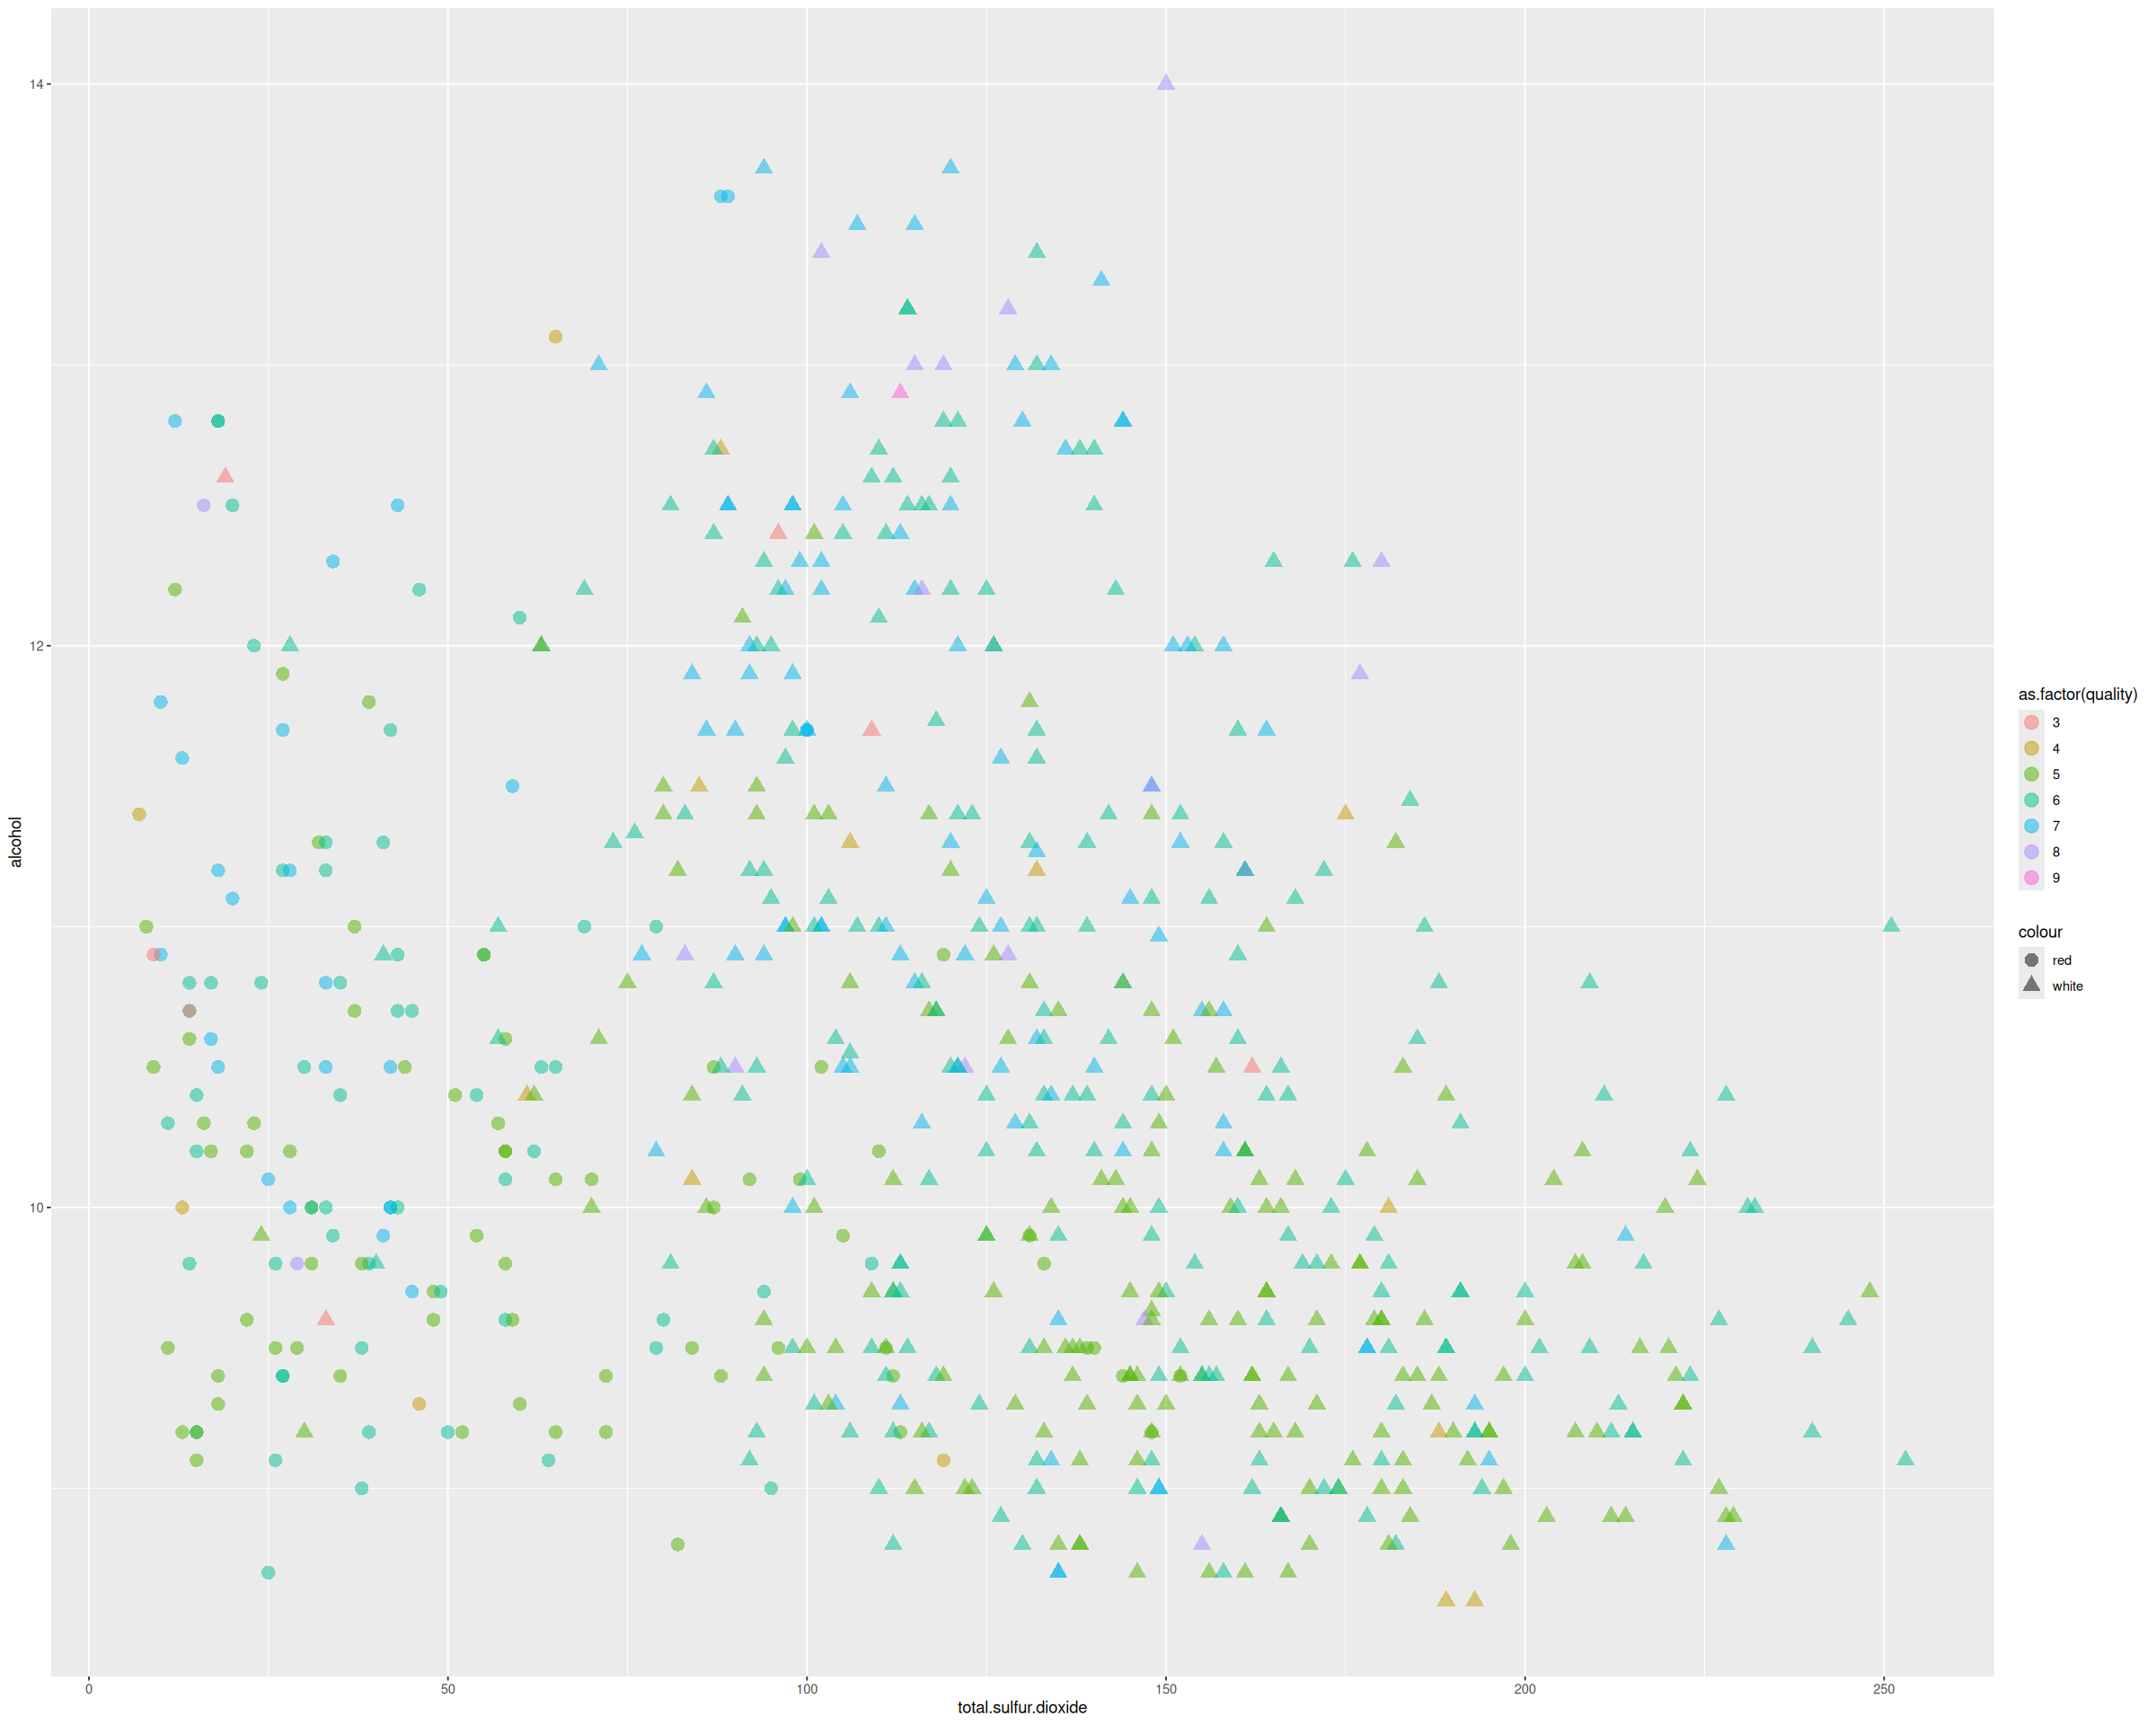

In [9]:
wine  %>% 
    ggplot(aes(x = total.sulfur.dioxide,
               y = alcohol,
               col = as.factor(quality),
               shape = colour))+
    geom_point(size = 4,alpha = 0.5)

**Figure legend:**

The legend shows the wine types "red" and "white" as circles and triangles respectively. Quality scores from 3 to 9 are indicated by colours. Quality scores from 3 to 6 are indicated by red, yellow, green, and teal, whereas higher scores from 7 to 9 are indicated by blue, purple, and pink.

**Pause and reflect:**
* What is the relationship between ***alcohol*** and ***quality*** for both types of wine?
* What type of wine tends to have a low ***total.sulfur.dioxide*** value?

Since the figure above is quite difficult to interpret, _k_-means clustering is applied to make this clearer.

#### 9. Scale and centre the data

In [10]:
wine_scaled  <- wine[,c(1:12)]  %>% 
    scale(center = TRUE, scale = TRUE)  %>% 
    as.data.frame()

#### 10. Determine the silhouette scores

**Hints:** 
* Create empty vectors `silhouette_vec` and `k`.
* Use `wine[,1:12]` as the argument for the `dist` function.

In [11]:
### BEGIN SOLUTION
silhouette_vec <- c()
k <- c()
### END SOLUTION

Determine the silhouette score for 2 to 20 clusters.

**Hints:** 
* Use the range `2:20`.
* Use `wine_scaled` as the data for the `kmeans` function.

In [12]:
### BEGIN SOLUTION
for (current_k in 2:20) {
    kmeans_model <- kmeans(wine_scaled, centers = current_k, nstart = 25)
    sil <- silhouette(kmeans_model$cluster, dist(wine_scaled))
    silhouette_avg <- mean(sil[, 3])
    silhouette_vec <- c(silhouette_vec, silhouette_avg)
    k <- c(k, current_k)
}
### END SOLUTION

Create a data frame `model_statistics` with the variables `silhouette_vec` and `k`.

In [13]:
### BEGIN SOLUTION
model_statistics <- data.frame(silhouette_vec = silhouette_vec, k = k)
### END SOLUTION

#### 11. Plot silhouette scores vs number of clusters

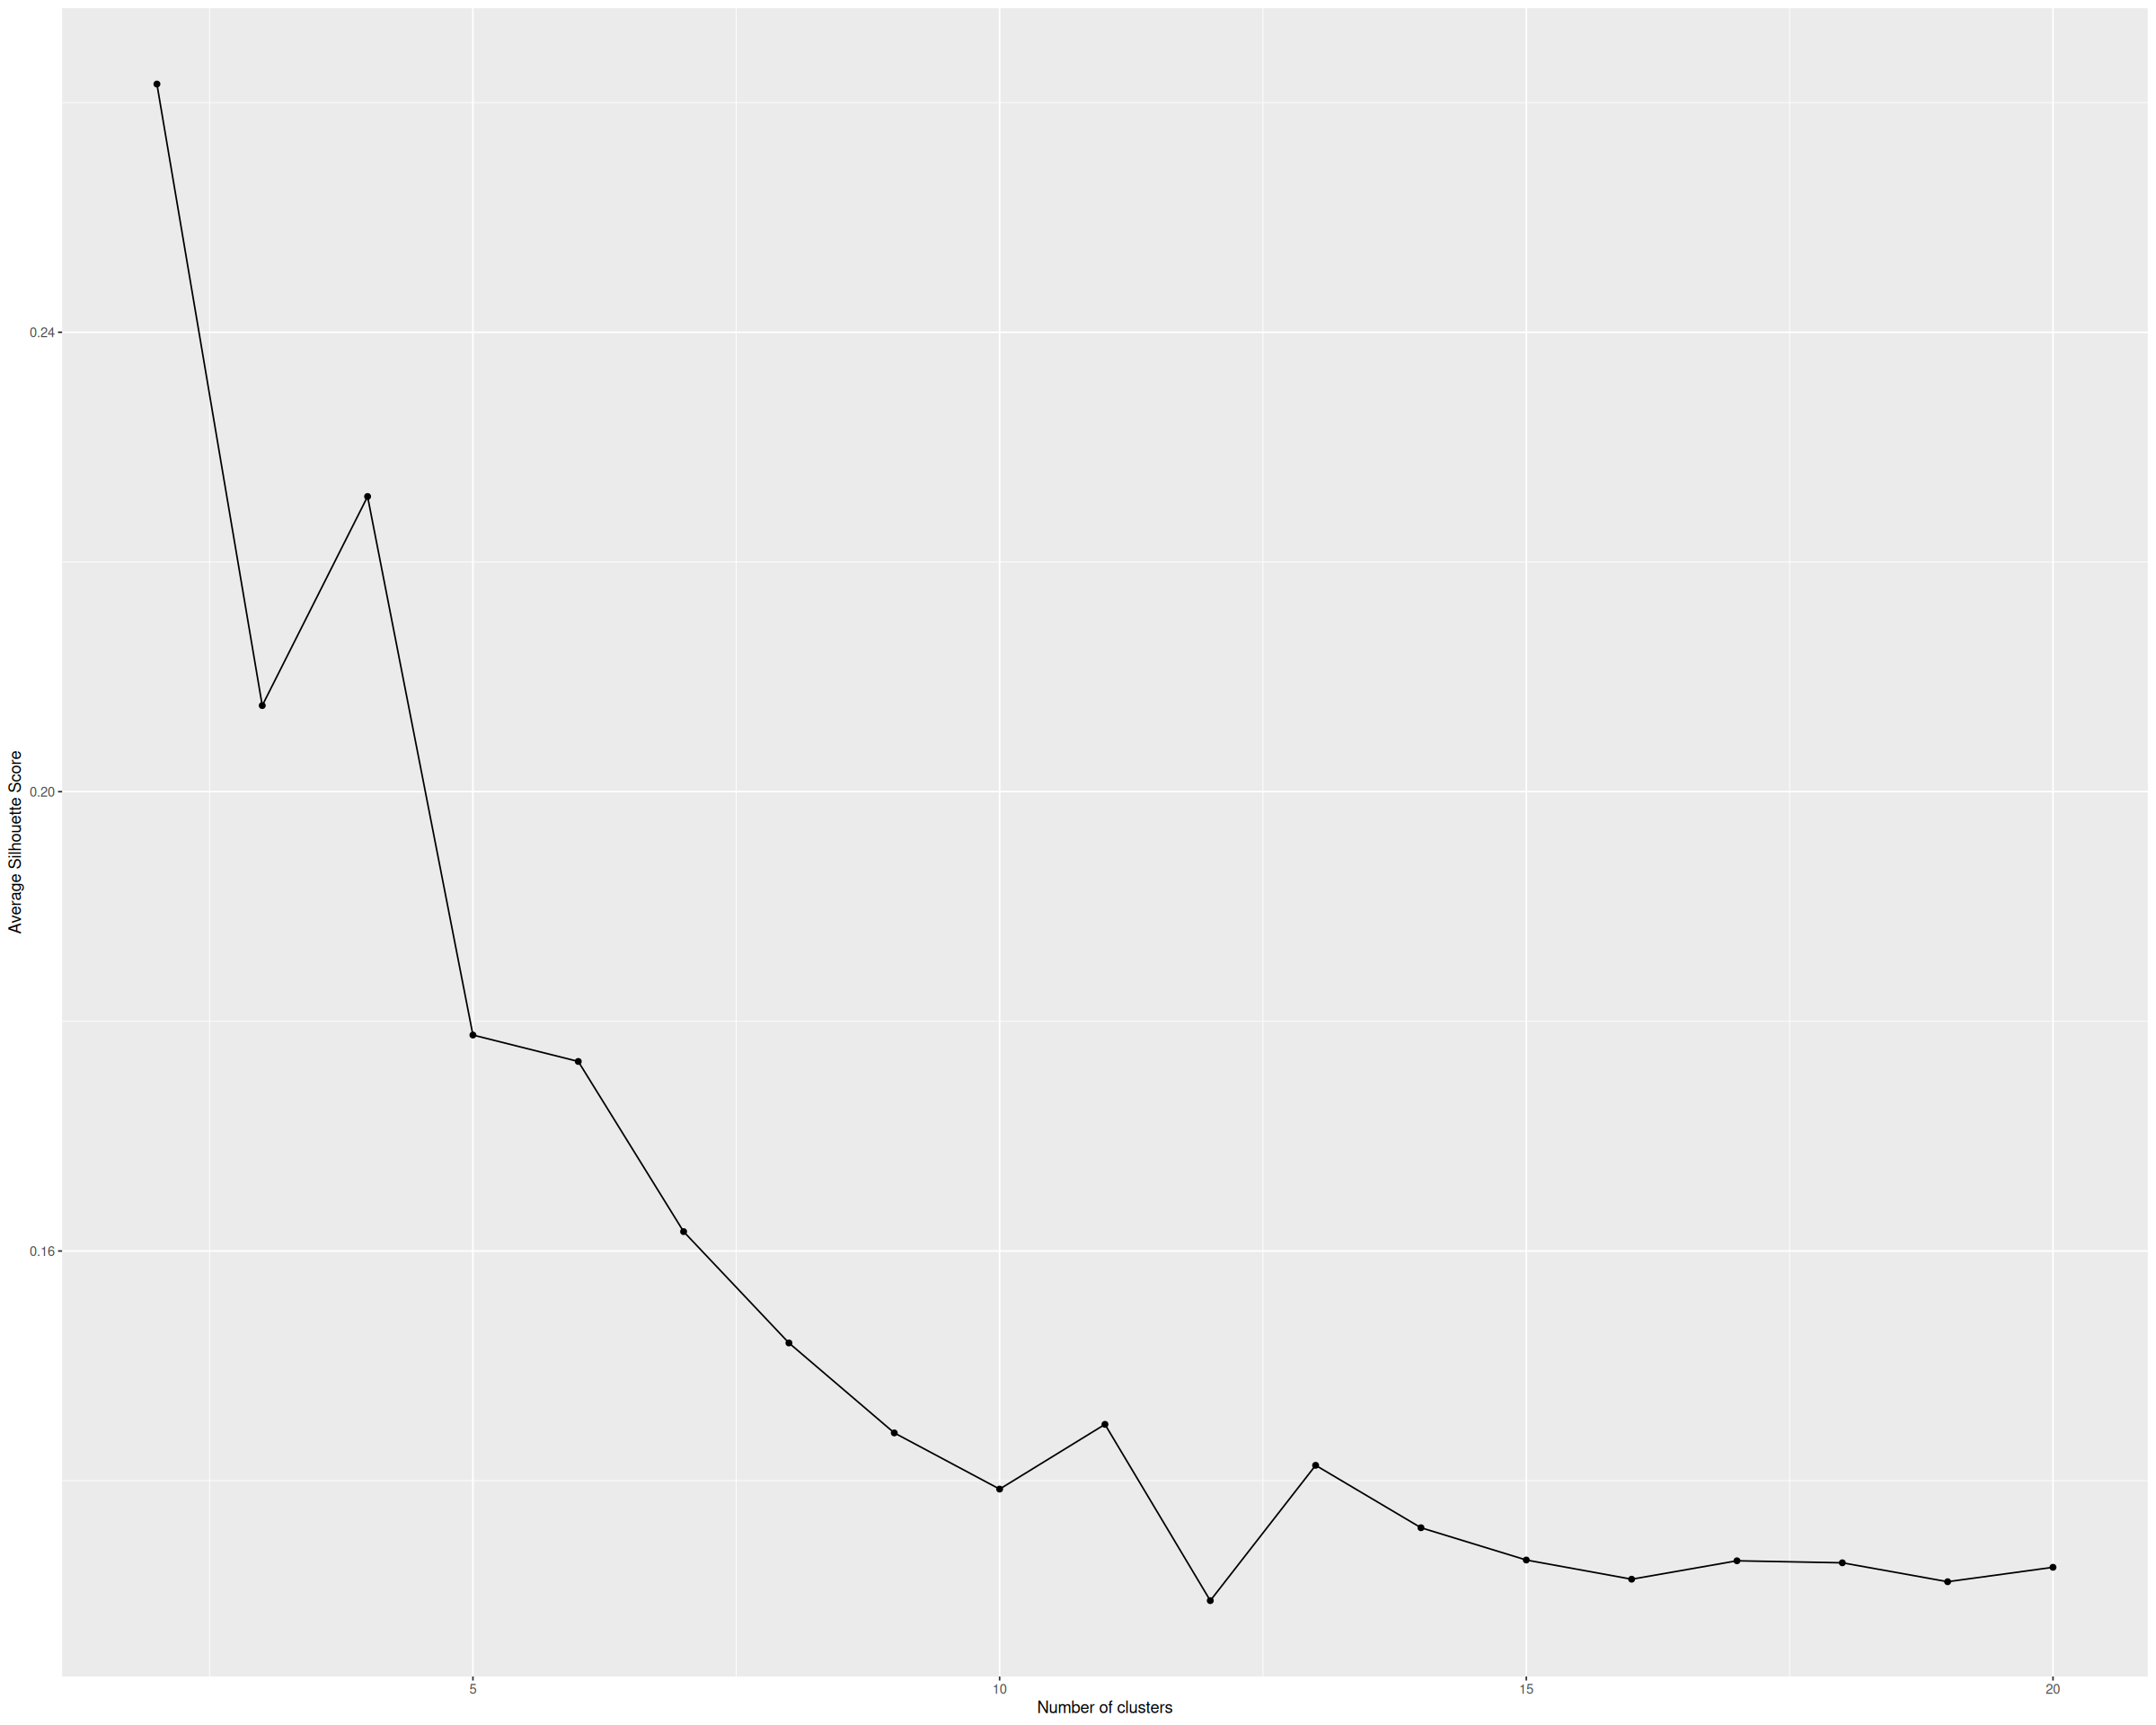

In [14]:
### BEGIN SOLUTION
ggplot(model_statistics, aes(x = k, y = silhouette_vec)) +
    geom_line() +
    geom_point() +
    xlab("Number of clusters") +
    ylab("Average Silhouette Score")
### END SOLUTION

**Pause and reflect:**
How many clusters would you choose based on the plot of silhouette scores and number of clusters?

#### 12. Apply _k_-means clustering with two clusters

**Hint:** Name the model `kmeans_model_2 <-`.

In [15]:
### BEGIN SOLUTION
kmeans_model_2 <- kmeans(wine_scaled, centers = 2, nstart = 25)
### END SOLUTION

#### 13. Plot the two clusters

**Note:** All the variables are used to find the clusters, but they are plotted in two dimensions. The variables ***alcohol*** and ***total.sulfur.dioxide*** are chosen since potential groups appeared to be separable in this plane in the plot generated in Step 8.

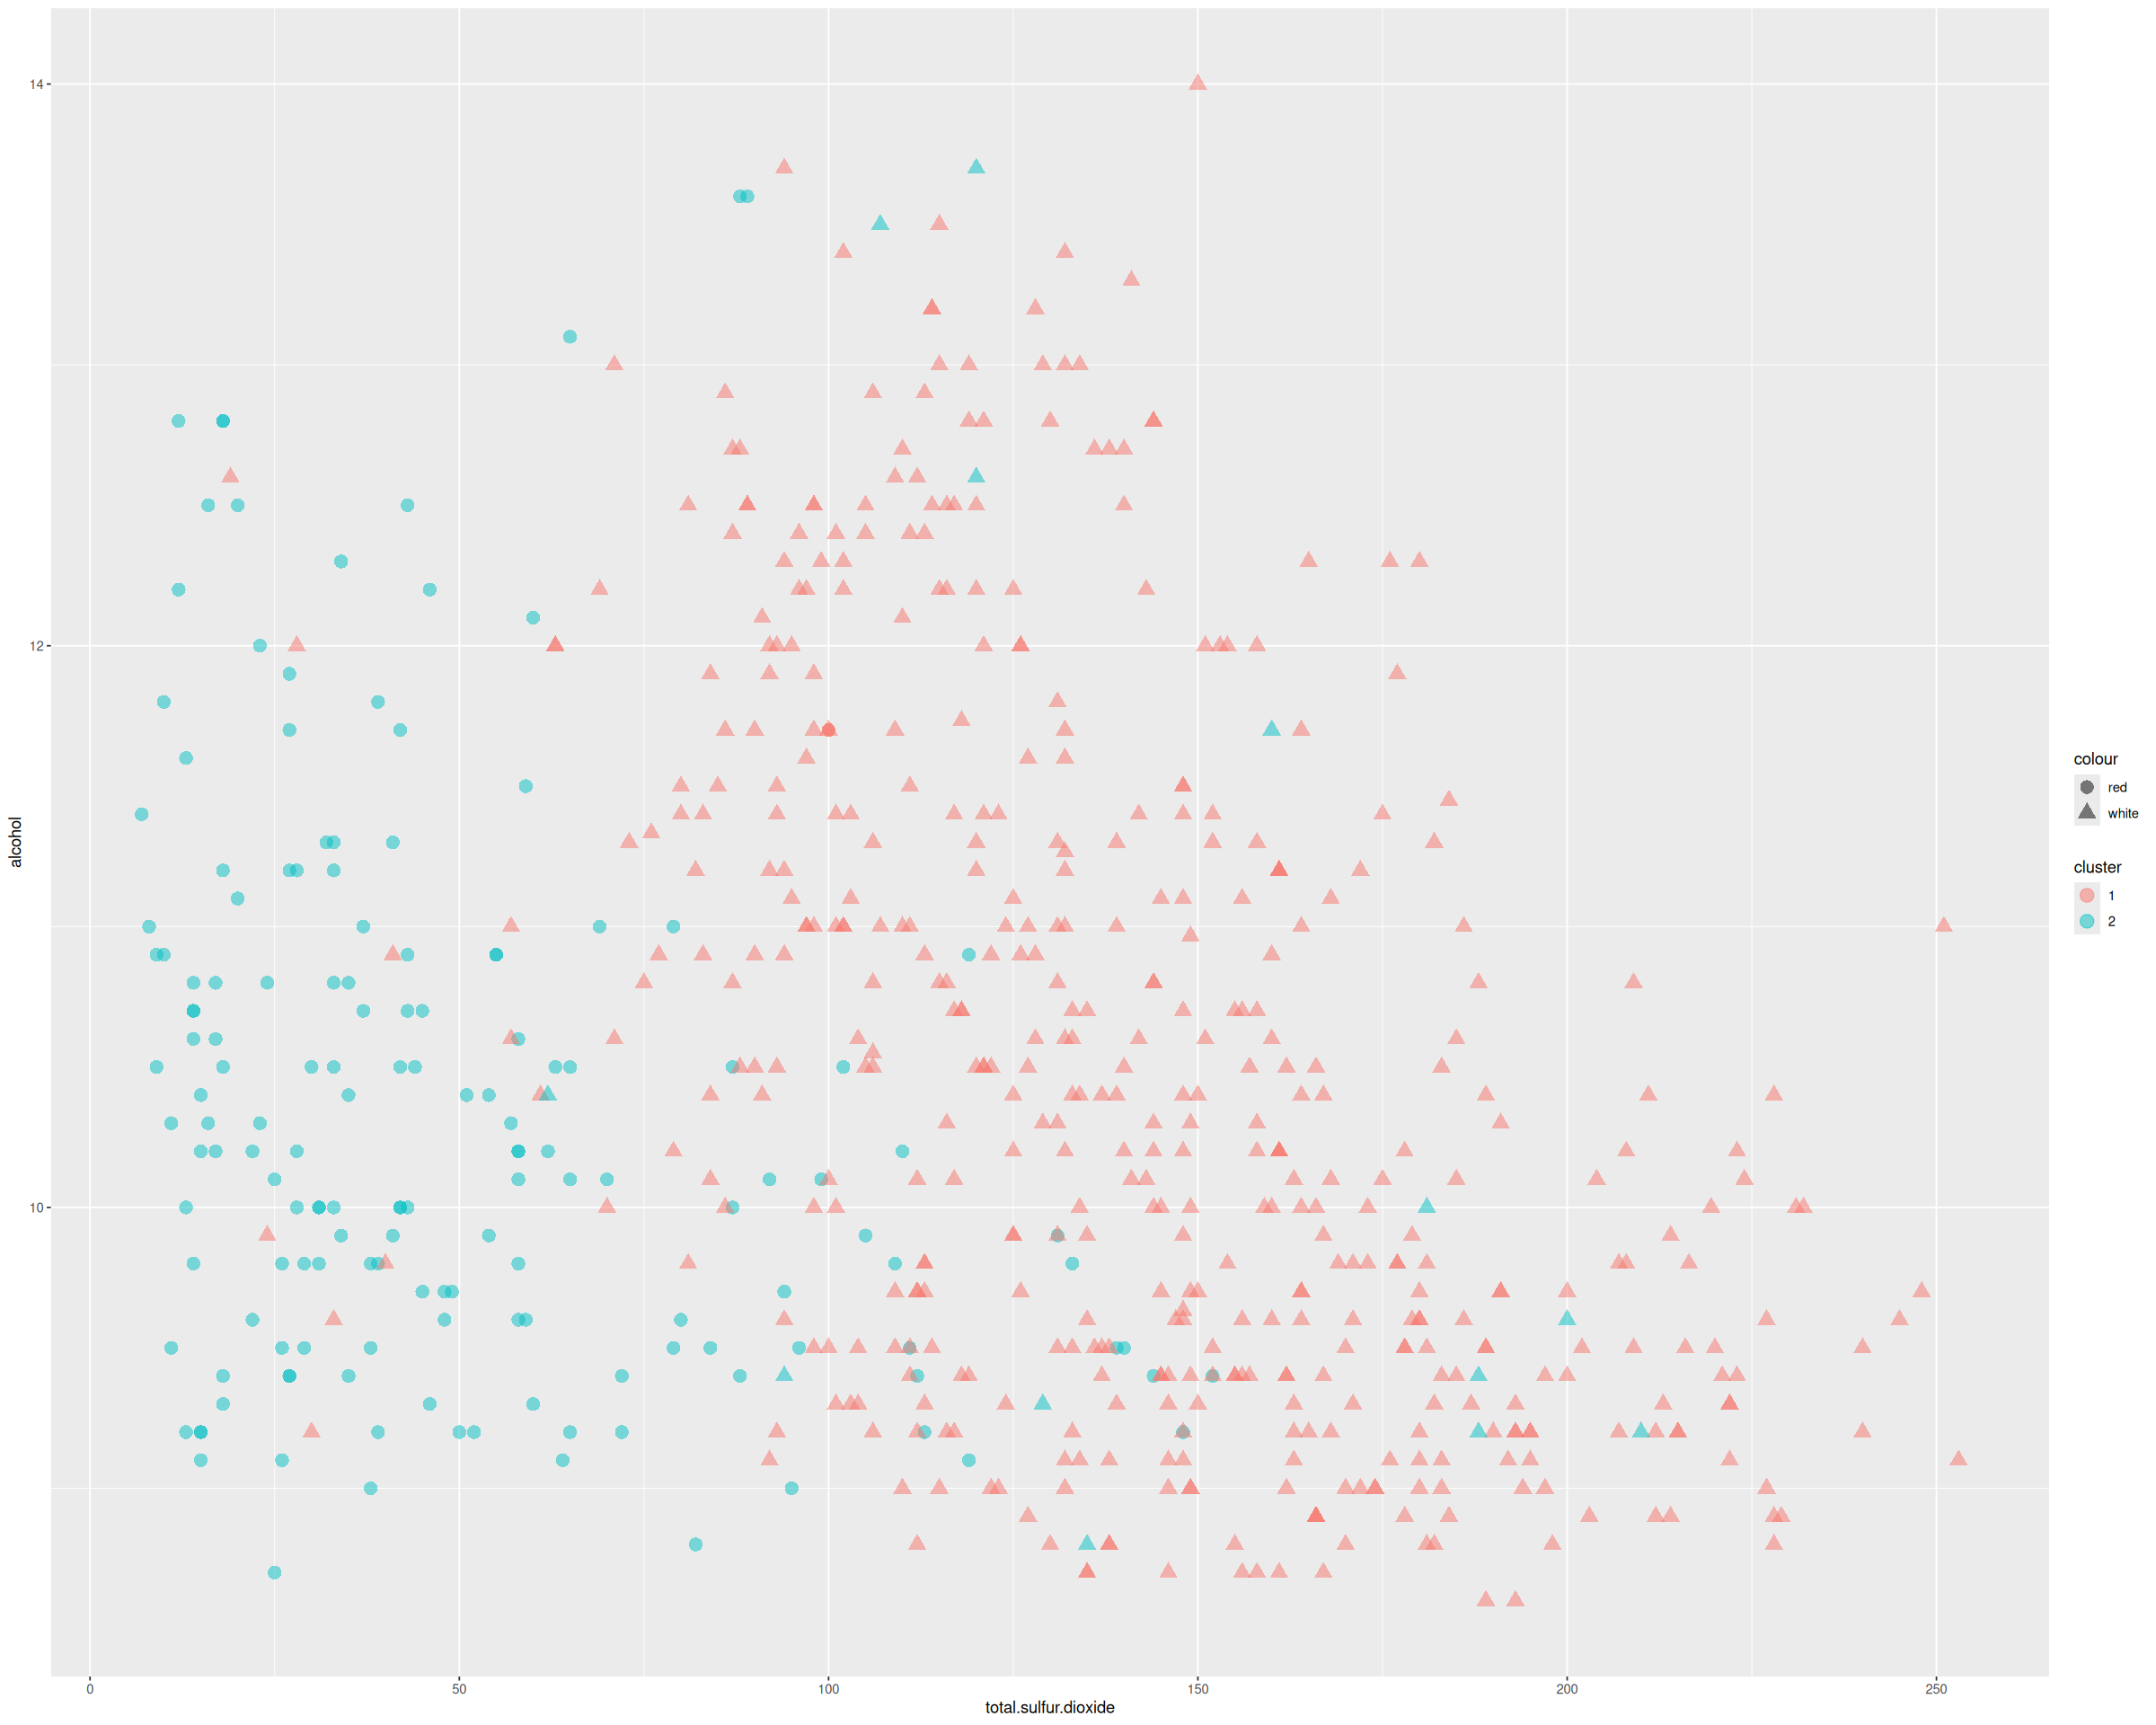

In [16]:
wine  %>% 
    mutate(cluster = as.factor(kmeans_model_2$cluster),
           colour = wine$colour)  %>% 
    ggplot(aes(x = total.sulfur.dioxide,
               y = alcohol,
               col = cluster,
               shape = colour)) +
    geom_point(size = 4,alpha = 0.5)

**Pause and reflect:**  
Notice that the algorithm has separated red and white wines. What insights can you gain from the clusters identified by the _k_-means model? How does the red group compare to the blue group? 

#### 14. Explore using three clusters with _k_-means clustering



**Hint:** Name the model `kmeans_model_3 <-`.

In [17]:
### BEGIN SOLUTION
kmeans_model_3 <- kmeans(wine_scaled, centers = 3, nstart = 25)
### END SOLUTION

#### 15. Plot the three clusters

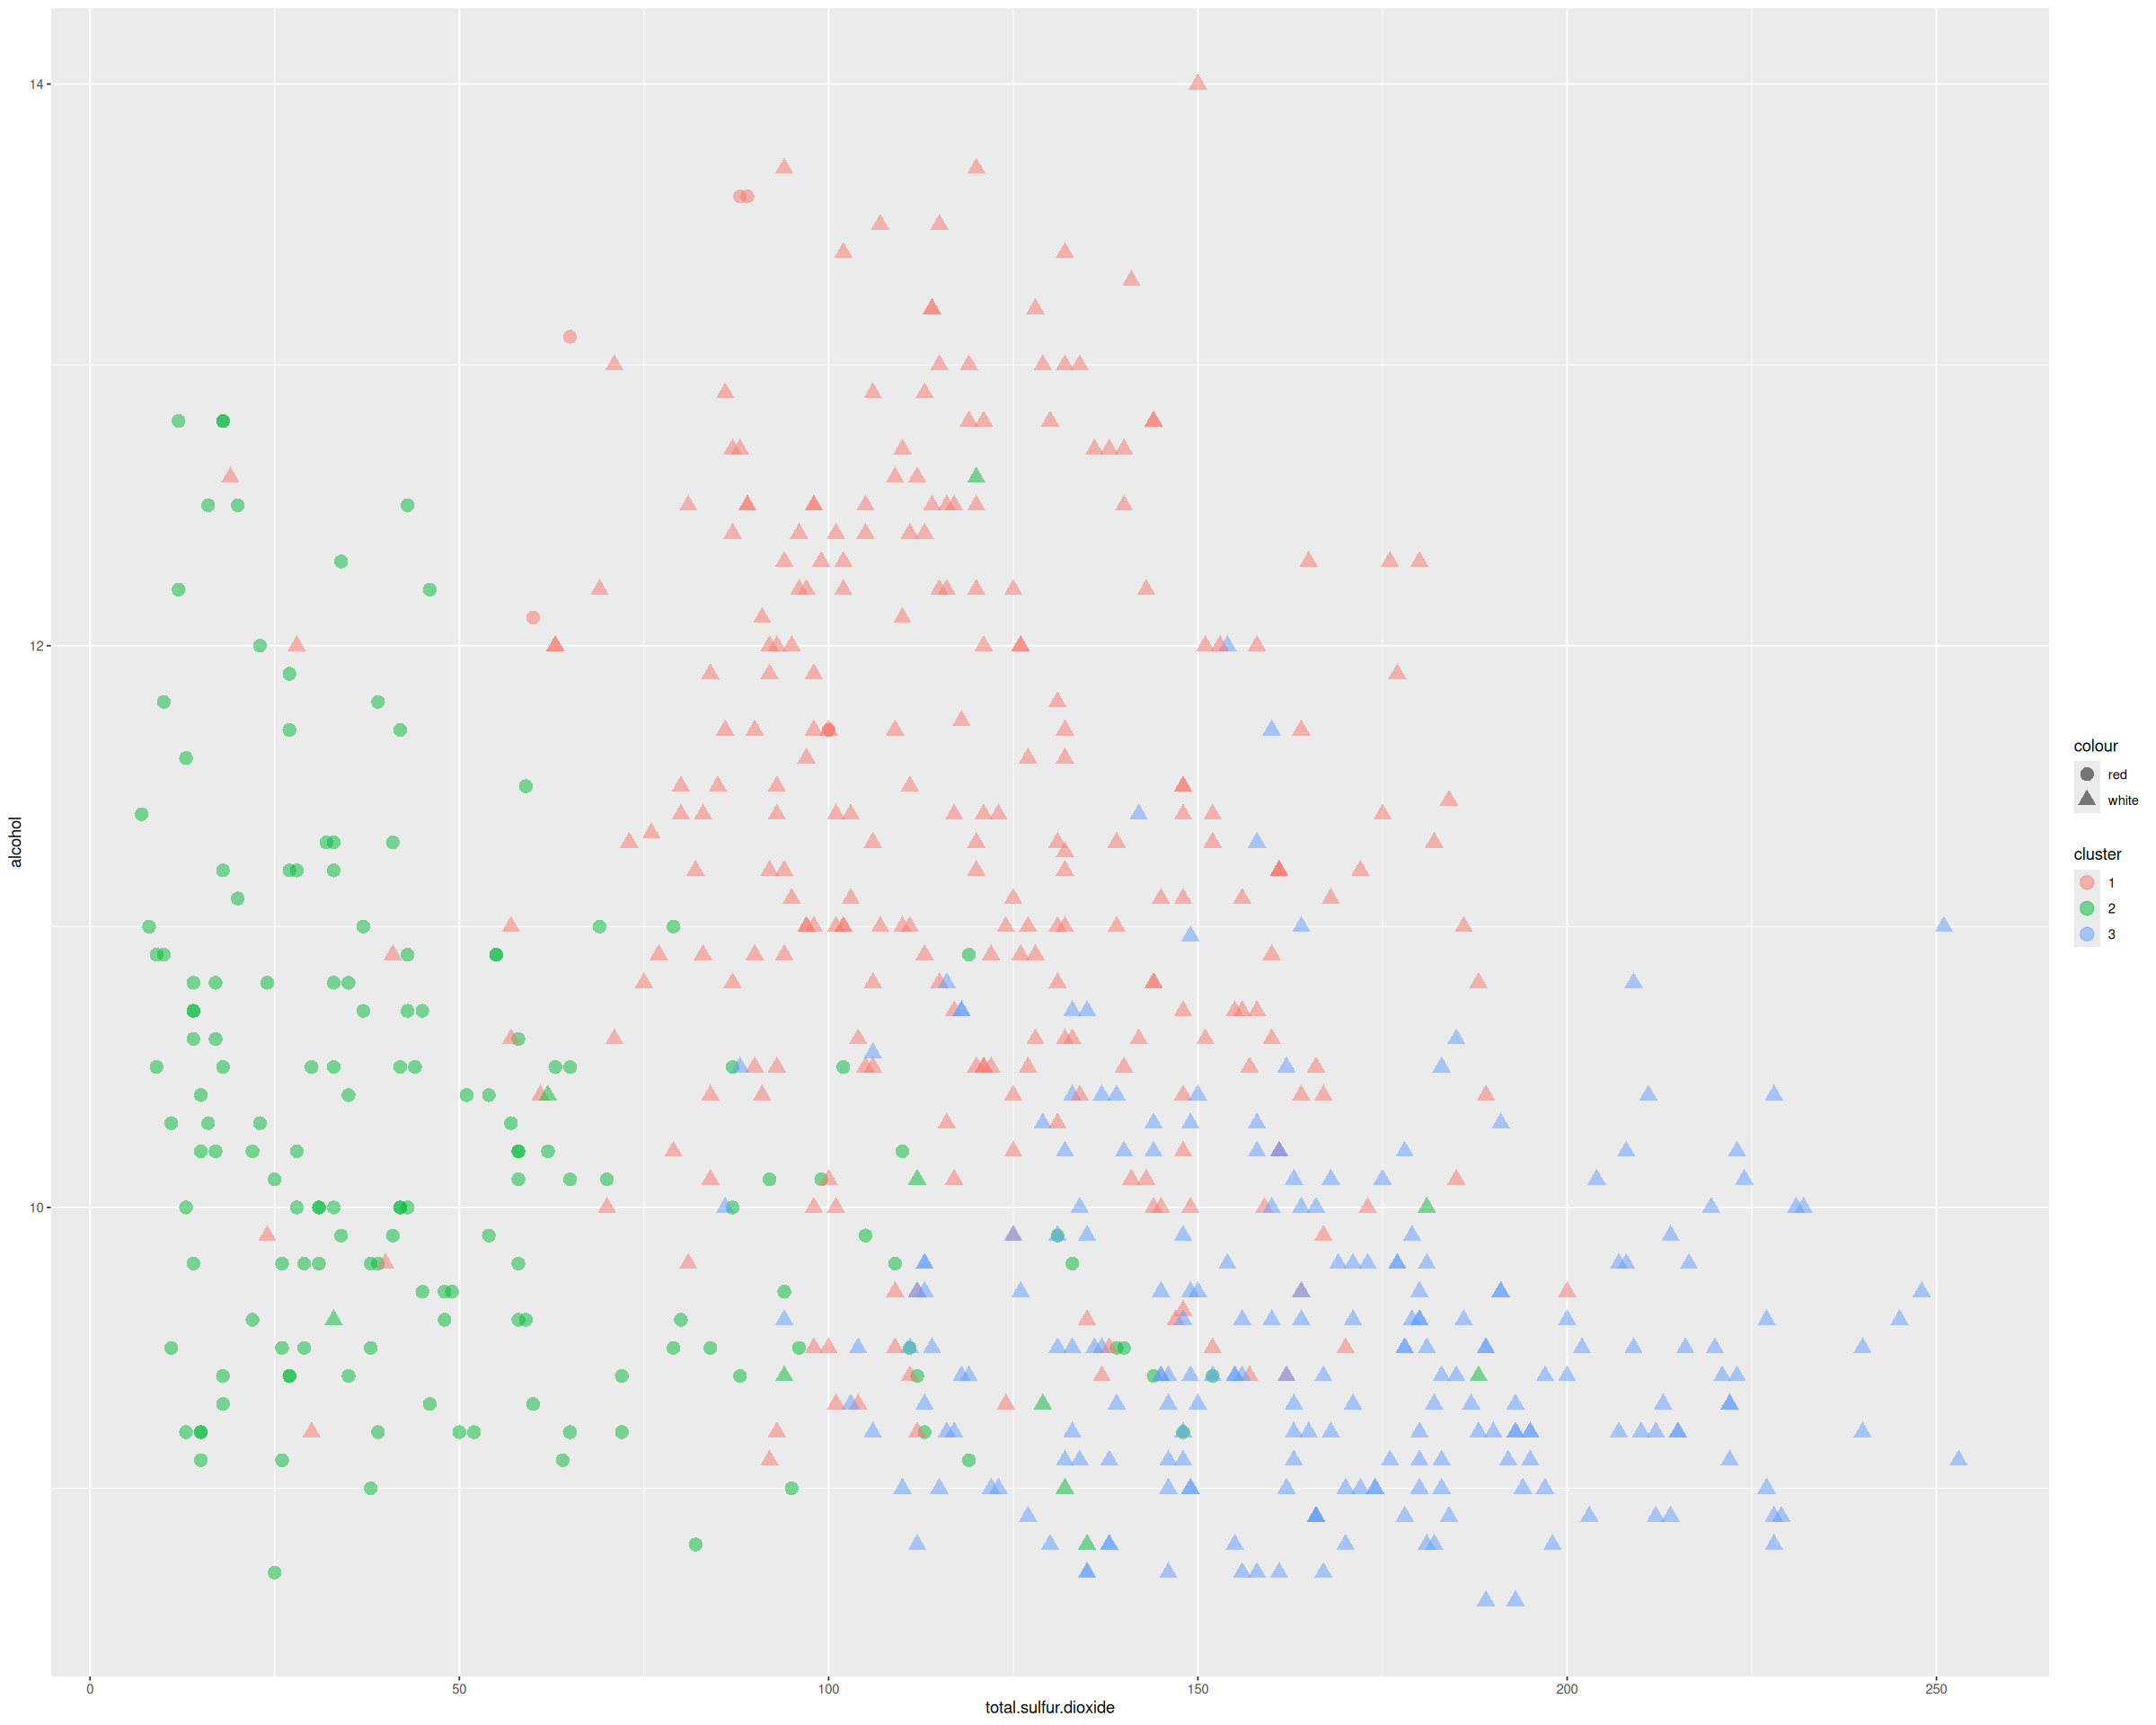

In [18]:
### BEGIN SOLUTION
wine  %>% 
    mutate(cluster = as.factor(kmeans_model_3$cluster),
           colour = wine$colour)  %>% 
    ggplot(aes(x = total.sulfur.dioxide,
               y = alcohol,
               col = cluster,
               shape = colour)) +
    geom_point(size = 4, alpha = 0.5)
### END SOLUTION

#### 16. Assign cluster labels to the average of each variable in the cluster

In [19]:
wine[,1:12]  %>% 
    mutate(clusters = kmeans_model_3$cluster) %>% 
    aggregate(by = list(.$clusters),
             FUN = mean)

Group.1,fixed.acidity,volatile.acidity,citric.acid,residual.sugar,chlorides,free.sulfur.dioxide,total.sulfur.dioxide,density,pH,sulphates,alcohol,quality,clusters
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,6.707224,0.2730798,0.3134221,3.411217,0.03817110,29.06084,117.77567,0.9920232,3.234487,0.4897338,11.30881,6.144487,1
2,8.368712,0.5420859,0.2624540,2.789264,0.08913497,16.61350,52.51534,0.9968936,3.291288,0.6417178,10.25153,5.588957,2
3,7.010360,0.2826126,0.3539640,11.125000,0.05254505,44.99099,168.17568,0.9970333,3.144775,0.4979730,9.55503,5.549550,3


Using the scatterplot and the table, notice that red wines are grouped together and the white wines are separated according to quality and alcohol content.

**Pause and reflect:**

What other insights can be gained from the scatterplot and the table? Which variable averages are different between clusters?

Up to this point, the different steps of executing _k_-means clustering were illustrated. In the steps that follow, hierarchical clustering is executed on the same data set to split the data into appropriate clusters.

#### 17. Apply hierarchical clustering and plot a dendrogram

**Hint:** Use the default options for the `hclust` function and name the model `hc <-`.


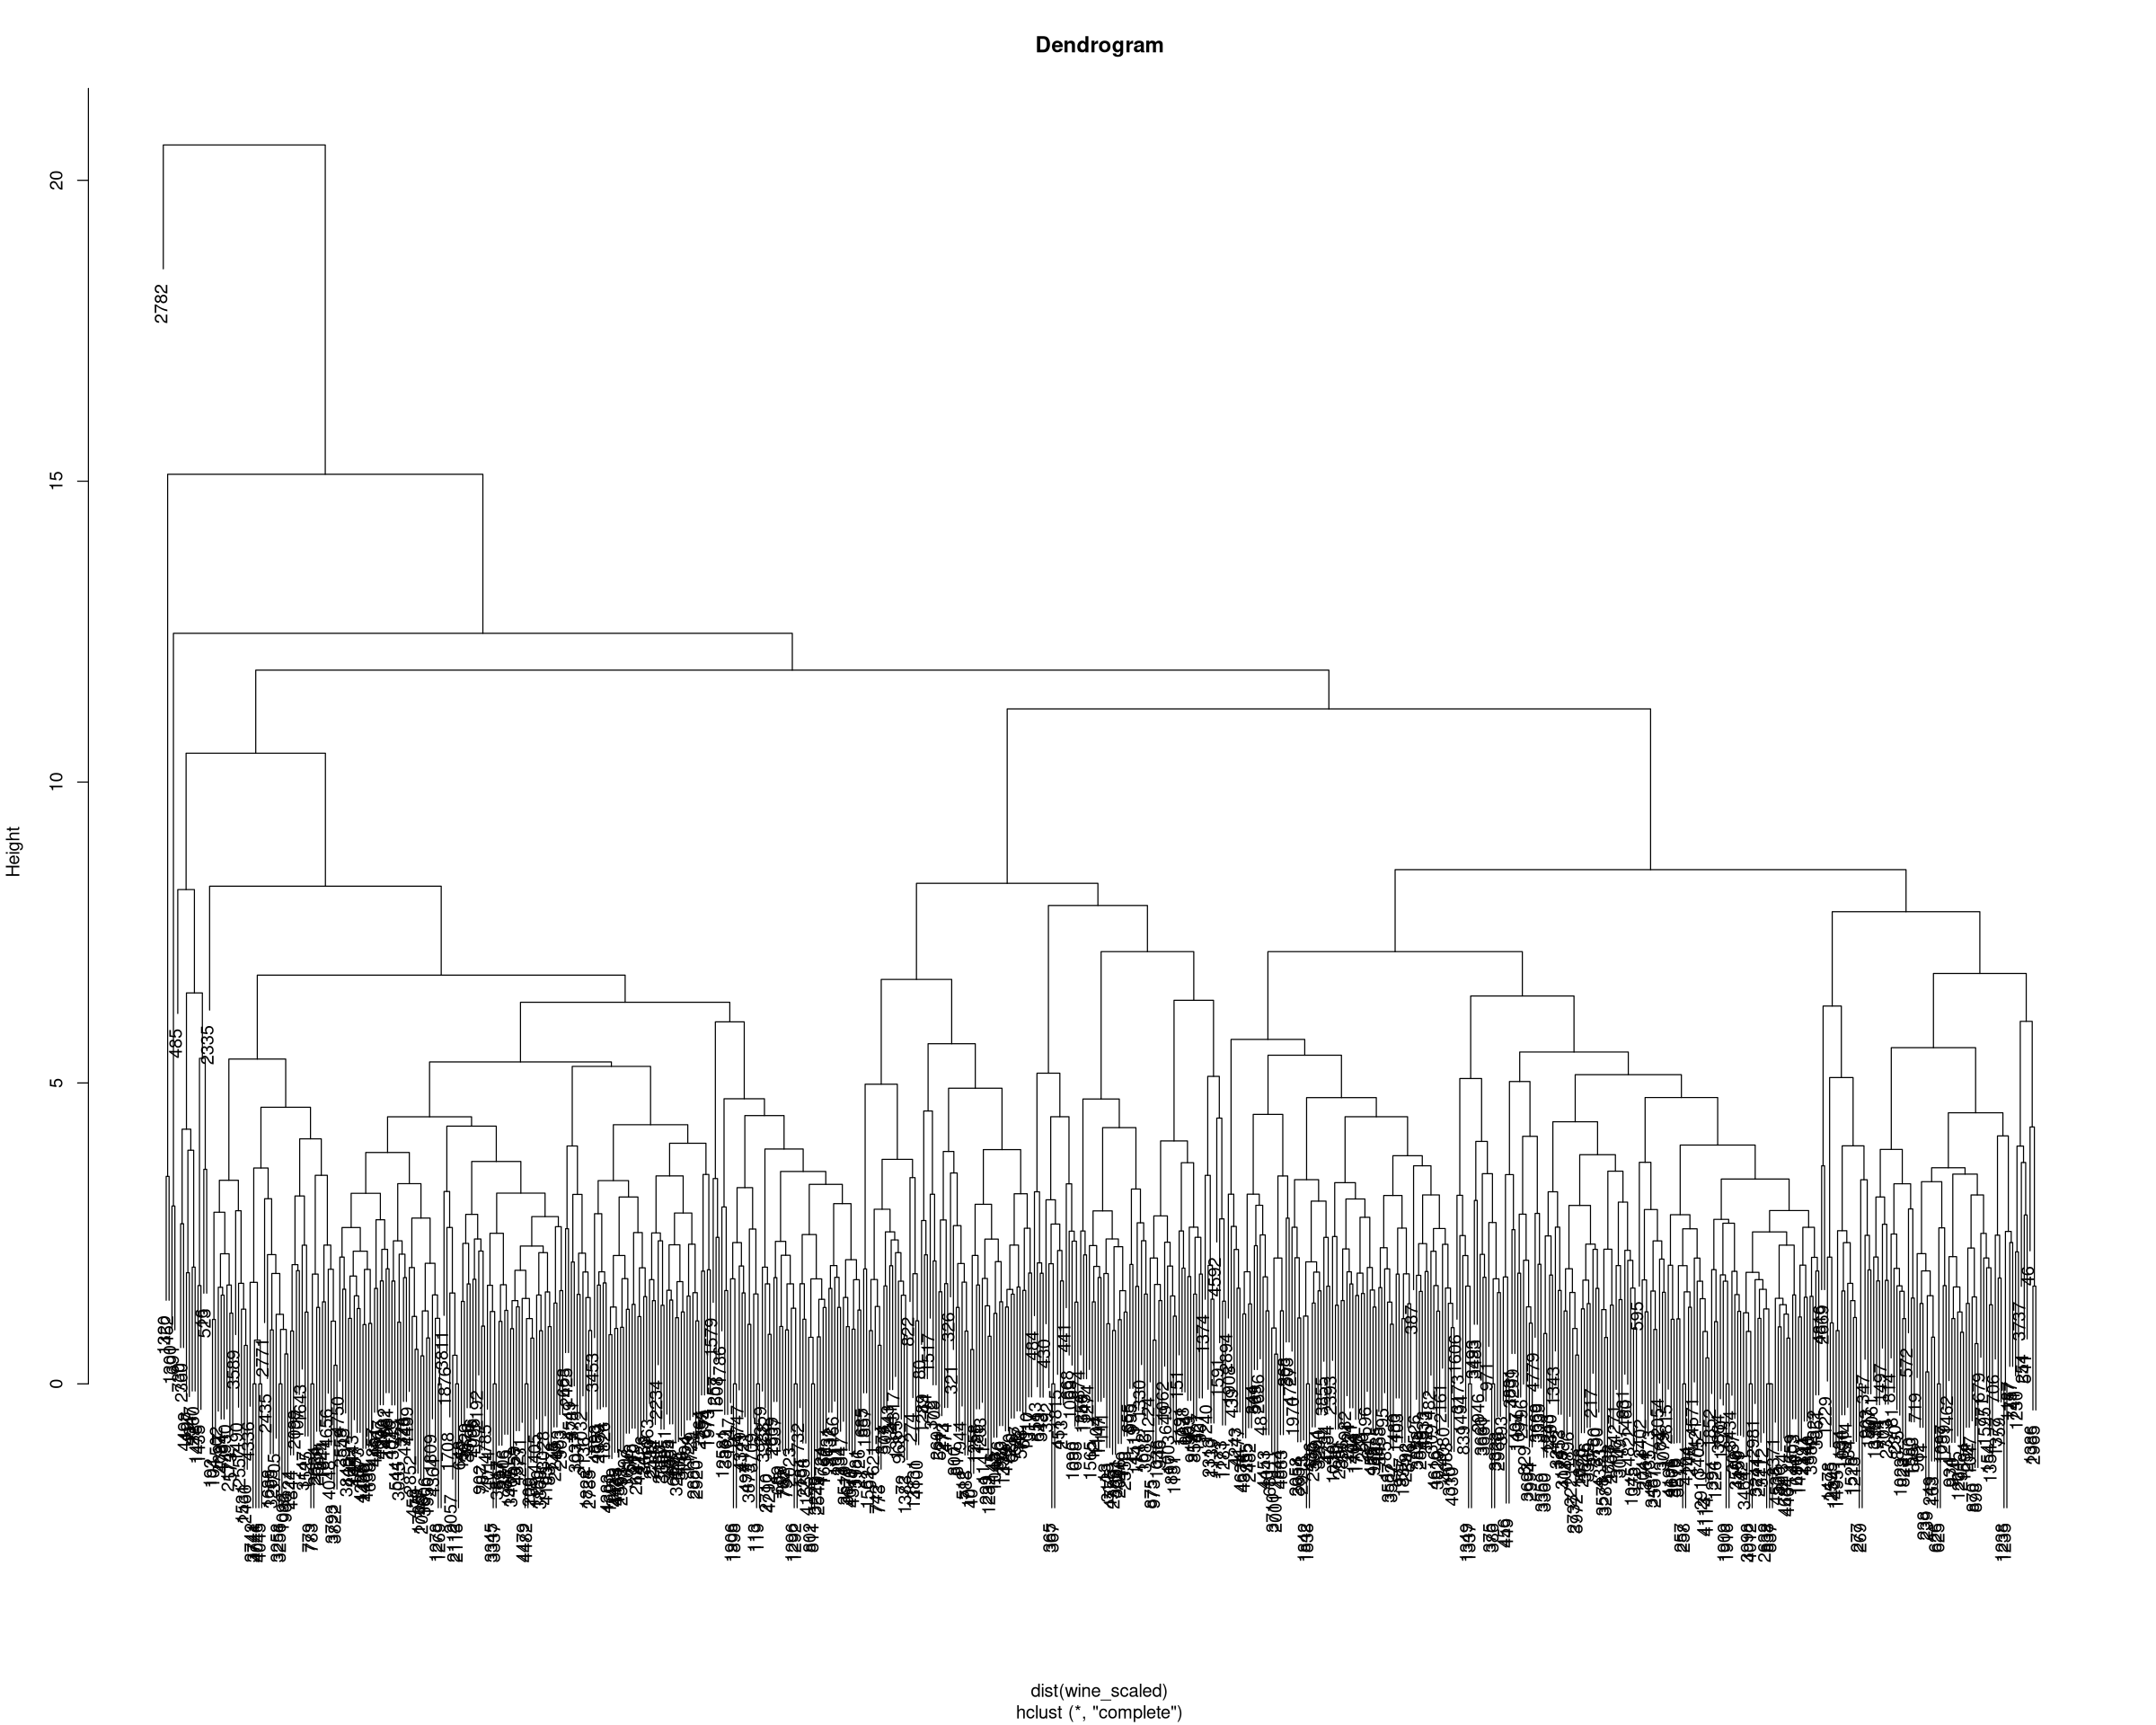

In [20]:
### BEGIN SOLUTION
# Apply hierarchical clustering
hc <- hclust(dist(wine_scaled))
# Plot the dendrogram
plot(hc, main = "Dendrogram")
### END SOLUTION

#### 18. Cut the dendrogram to form two clusters and plot the clusters

**Hint:** Use `hcluster_2 <- cutree(...`

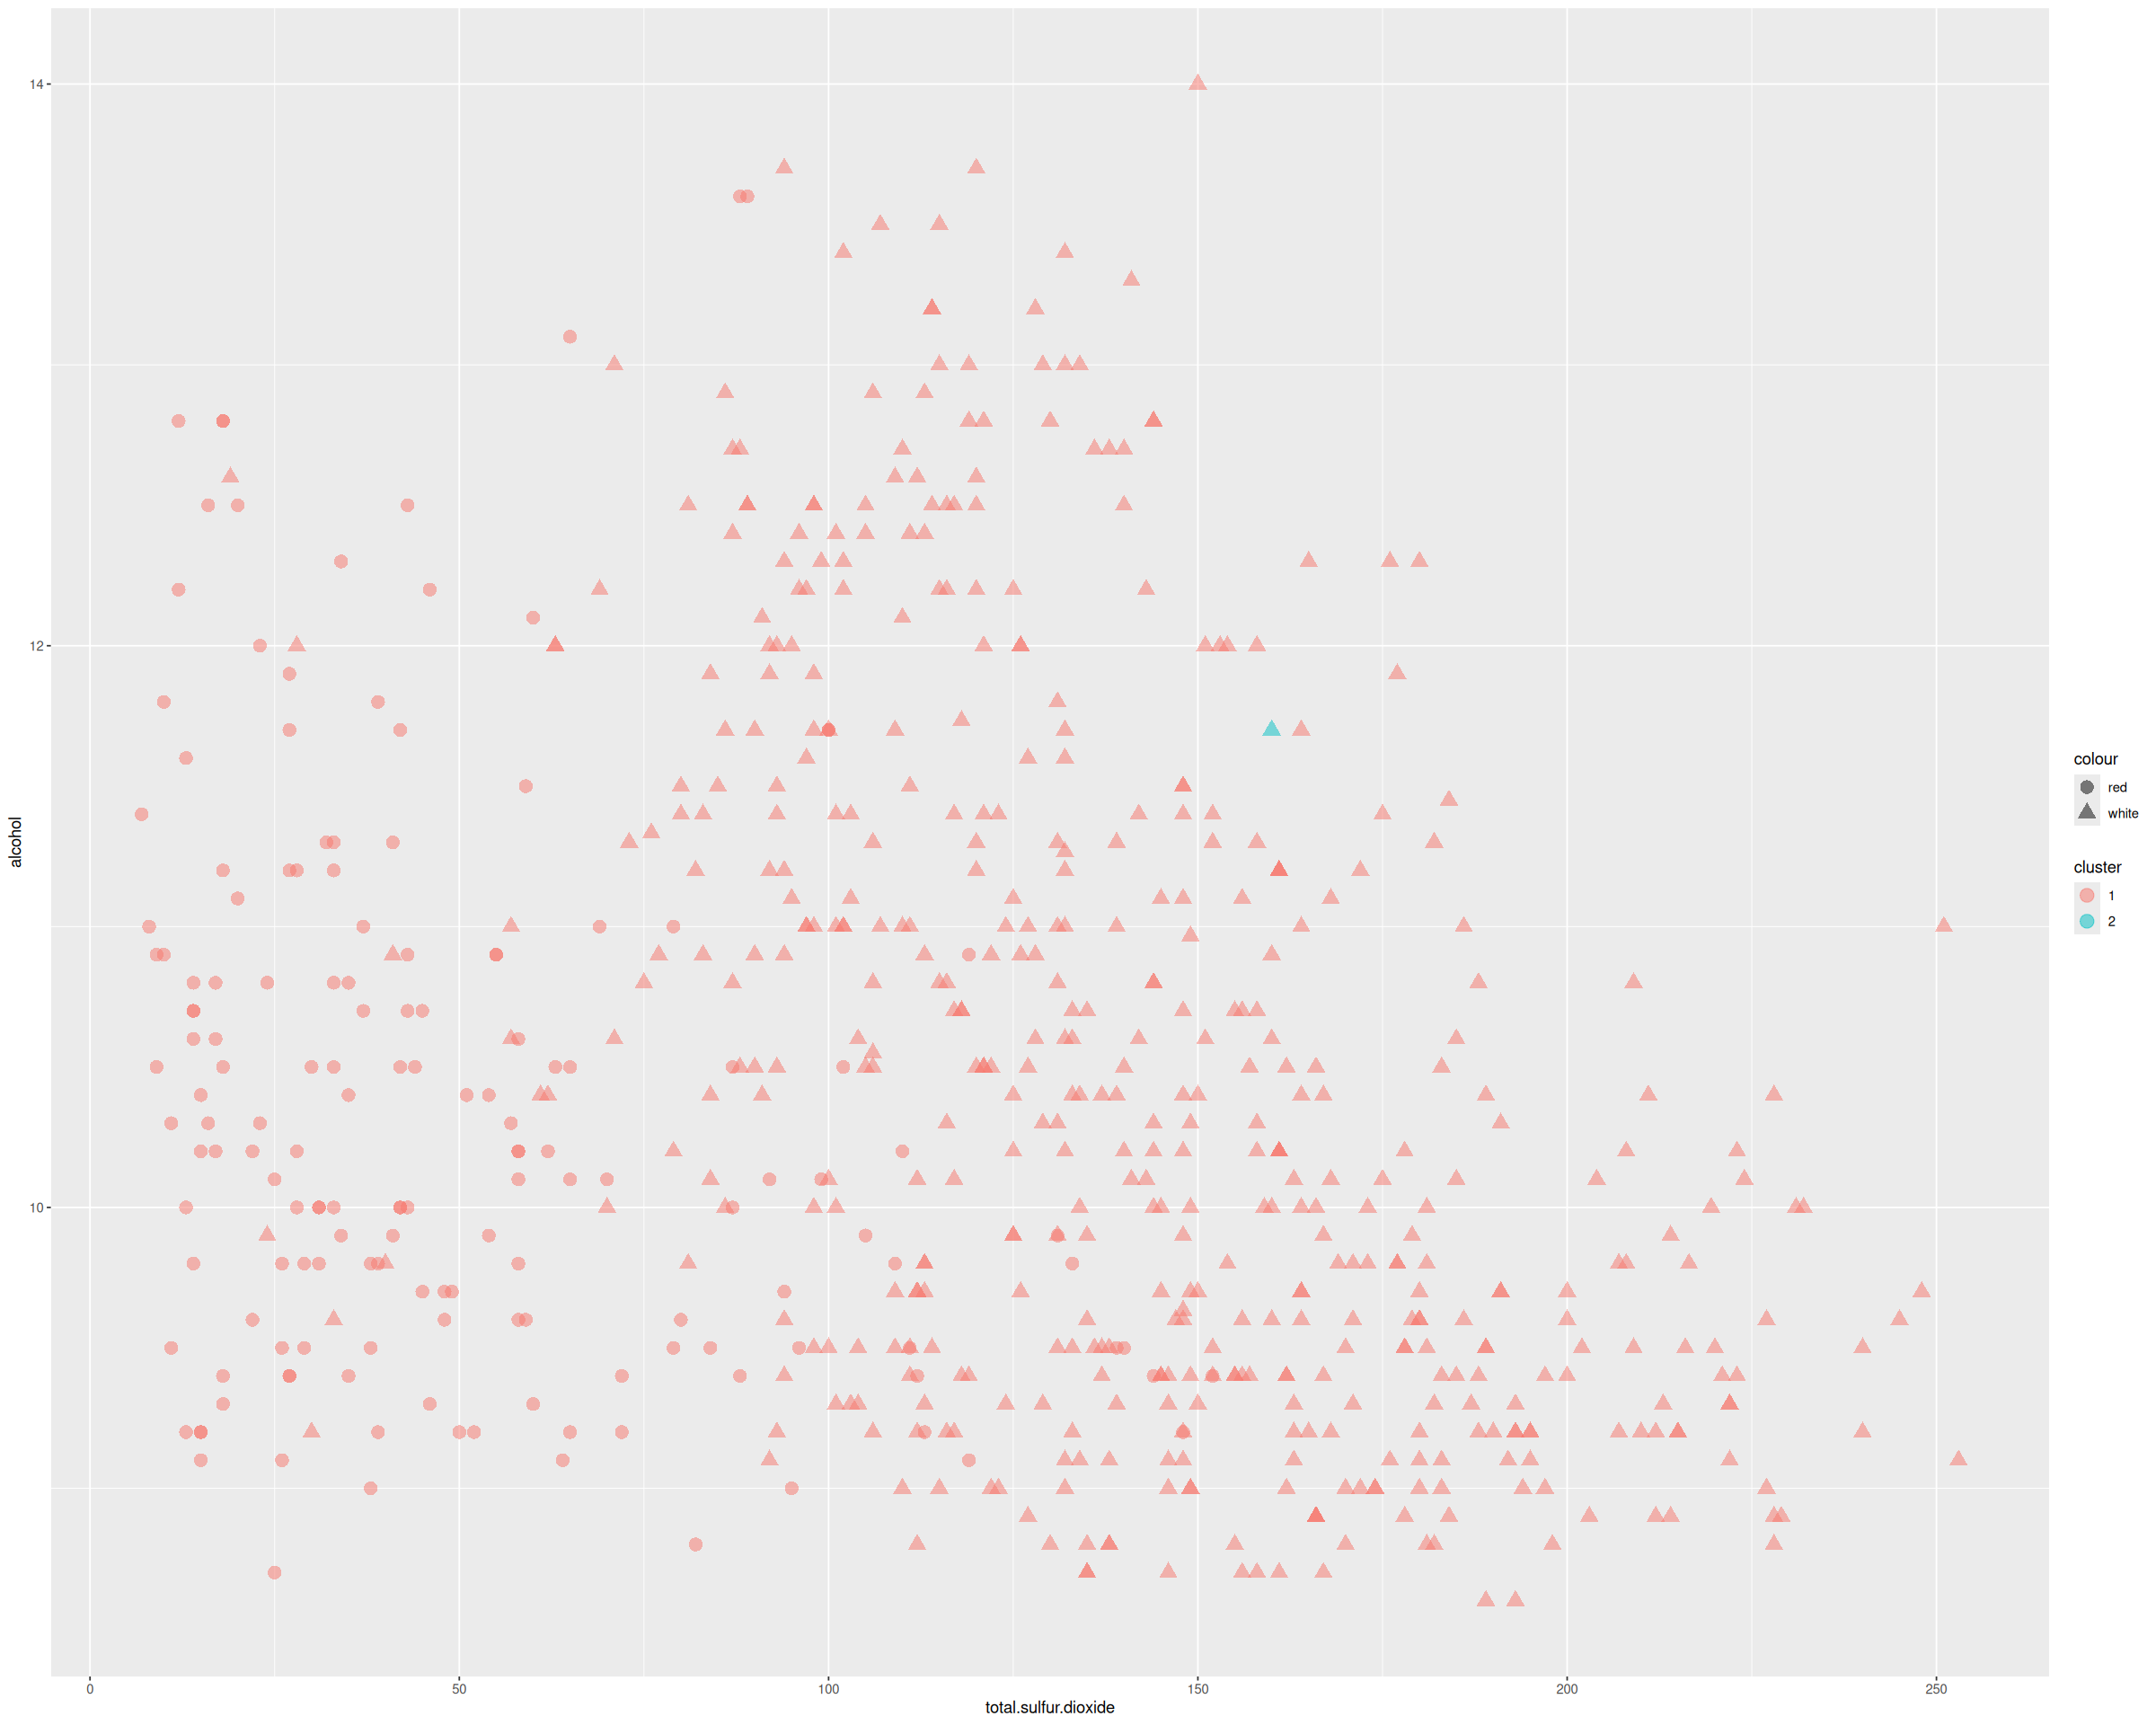

In [21]:
### BEGIN SOLUTION
hcluster_2 <- cutree(hc, k = 2)
### END SOLUTION

# Plot the clusters
wine  %>% 
    mutate(cluster = as.factor(hcluster_2),
           colour = wine$colour)  %>% 
    ggplot(aes(x = total.sulfur.dioxide,
               y = alcohol,
               col = cluster,
               shape = colour)) +
    geom_point(size = 4,alpha = 0.5)

Notice the similarity to the output of _k_-means 
with  `k = 2 `. It appears to cluster the red and white wines. 





#### 19. Cut the dendrogram to form three clusters and plot the clusters

In [22]:
### BEGIN SOLUTION
hcluster_3 <- cutree(hc, k = 3)
### END SOLUTION

**Pause and reflect:**

How do the three clusters generated in this step compare to the three clusters found in Step 15 when _k_-means clustering was applied to the same data set?

**Note:** Remember to submit this IDE notebook after completion and navigate to the activity submission in the next component to submit the written part of this assessment. 